# Geographic gating of genus predictions: CD275k, 768 px

**Question.** How much does the CD275k 768 px model's genus prediction improve if, for each source, we remove every genus
that is not known from the source's biogeographic realm?

**Setup** (same as `nbs/Coral_Taxon_Diversity_Live_CD275k_Res768_Regions.ipynb`):
- **Model**: `cbm_cd275000_res768` at step 50k, 768 px (KL w=0.5, the taxv2 concept table). Its genus head is one softmax over 367 genus
  channels (all phyla, plus `none`).
- **Sources**: the 18 test sources reliably labelled to genus, each assigned to a MEOW realm by `REGIONS`.
- **Live hard coral**: the KL05 rules (order head = scleractinia and P(live) > 0.5 for the model; `order__scleractinia`
  and `live` positive for the annotations).

**Which genera a realm allows** (from `inat/iNat_Genus_Realm_Presence.ipynb`):

| method | allowed genera in realm *r* |
|---|---|
| `base` | all (the KL05 model as is) |
| `gate iNat+ann` | ≥ 1 iNat observation in *r*, **or** ≥ 1 annotated point in a CoralNet train/val source in *r* (`genus_realm_presence_combined.csv`). No test labels are used. |

Gating sets the probability of the genera a realm doesn't allow to 0 (logit −∞) and renormalizes over the rest.
Genera with no data (no iNat records and no annotations anywhere, plus the `none` channel) are never gated.

**Prediction rule (every method).** The genus is the argmax only if its probability is **> `THRESH` = 0.5**;
otherwise the point gets the label **`uncertain`**. For a gated method the probability is the renormalized one, so
removing genera raises confidence and can turn `uncertain` into a genus.

**Evaluation.**
1. **Point classification**: annotated live hard coral points with a hard coral genus label. A point predicted
   `uncertain` or a non-coral genus counts as wrong. Metrics:
   - accuracy, balanced accuracy (mean per-genus recall), macro F1 and support-weighted F1 over the annotated genera;
   - **coverage**: the share of points that get a genus rather than `uncertain`;
   - **selective accuracy**: accuracy on the points that get a genus.

   Per source, per realm, pooled. The pooled differences get paired 95% bootstrap CIs (resampling images).
2. **What changes**: correct / wrong / `uncertain` before vs after gating, and base → gated transition matrices,
   pooled and per realm.
3. **Diversity at the points** (end to end, as KL05 *model, at the points*): richness, effective number, genus-list
   precision and recall, composition similarity. `uncertain` points contribute no genus.

Inputs: `inat/data/gating_cd275k_res768/` from `inat/gating_dense_predict.py --with-points` (`slurm/gating_predict_768.sbatch`): the genus softmax at every annotated point and the gated all-pixel shares. The gate is the same as in `Genus_Geographic_Gating.ipynb` (`inat/data/gating/gate_allow.json`). "KL05" in the checks below means this model's reference diversity run.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D

ROOT = Path.cwd() if (Path.cwd() / "configs").exists() else Path.cwd().parent
GATE_DIR = ROOT / "inat/data/gating_cd275k_res768"
INAT_OUT = ROOT / "inat/outputs"
OUT = INAT_OUT / "gating_cd275k_res768"
OUT.mkdir(parents=True, exist_ok=True)
CSV = ROOT / "nbs/model_checkpoints/cbm_scratch100k_kl_w0.5_taxv2/class_to_concepts.csv"
KL05 = ROOT / "eval_out/taxon_diversity/test_cd275k_res768_step50000_viable.parquet"  # this model's reference run
THRESH = 0.5          # a genus is predicted only if its (renormalized) probability is above this, else "uncertain"
B, SEED = 1_000, 0
TOP_N = 25            # transition matrices: genera beyond the top TOP_N per axis are pooled into "other"

REGIONS = {  # MEOW realm -> sources, as in Coral_Taxon_Diversity_Live_KL05_Regions.ipynb
    "Tropical Atlantic": [1304, 1642, 4091, 5181, 6494, 6702, 7049],
    "Western Indo-Pacific": [2615, 2616, 4721, 4342, 4816],
    "Central Indo-Pacific": [290, 1776, 3350, 6673, 2052, 2955, 3606, 6391, 4957, 7116],
    "Eastern Indo-Pacific": [1990, 2682, 3357, 4280, 6551, 6405, 3697, 5227],
    "Temperate Australasia": [2311, 2655, 3656],
}
REGION_OF = {s: r for r, ss in REGIONS.items() for s in ss}
REGION_COLOR = dict(zip(REGIONS, ["#2a78d6", "#d4a106", "#1baf7a", "#eb6834", "#8a4fd0"]))
REALM_ABBR = {"Tropical Atlantic": "TA", "Western Indo-Pacific": "WIP", "Central Indo-Pacific": "CIP",
              "Eastern Indo-Pacific": "EIP", "Temperate Australasia": "TAus"}
MAIN = "gate iNat+ann"
METHODS = ["base", MAIN]
GATES = [MAIN]
M_STYLE = {  # colour, marker, filled
    "base": ("#6b6a64", "o", True), "gate iNat+ann": ("#1c5cab", "D", True),
}
INK, MUTED, GRID, SURFACE = "#1c1c1a", "#6b6a64", "#e4e3df", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seqblue", ["#e8f1fc", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 40)
rng = np.random.default_rng(SEED)

pts = pd.read_parquet(GATE_DIR / "points.parquet")
P = np.load(GATE_DIR / "genus_probs.npy", mmap_mode="r")
GENERA = np.array(json.loads((GATE_DIR / "genus_names.json").read_text()))
assert len(P) == len(pts) and P.shape[1] == len(GENERA)
UNC = len(GENERA)                                 # index of the "uncertain" label
LABELS = np.append(GENERA, "uncertain")
NL = len(LABELS)
L_IDX = {g: i for i, g in enumerate(LABELS)}
pts["region"] = pts.source_id.map(REGION_OF)
assert pts.region.notna().all()

csv = pd.read_csv(CSV, dtype=str)
TAXA = sorted(set(csv.loc[csv["order"].str.lower() == "scleractinia", "genus"].dropna().str.lower())
              - {"not_given", "none"})
IS_SCLER = np.append(np.isin(GENERA, TAXA), False)  # over LABELS; "uncertain" is not a genus
SOURCES = [s for r in REGIONS for s in REGIONS[r] if s in set(pts.source_id)]
print(f"{len(SOURCES)} sources, {pts.image_id.nunique():,} images, {len(pts):,} points, "
      f"{len(GENERA)} genus channels ({IS_SCLER.sum()} hard coral)")

# Check: the ungated argmax reproduces the KL05 run's per-point genus prediction.
kl = pd.read_parquet(KL05, columns=["source_id", "image_id", "pred_genus", "pred_live"])
kl = kl[kl.source_id.isin(SOURCES)]
key = lambda d: d.groupby(["source_id", "image_id"]).cumcount()
m = (pts[["source_id", "image_id", "pred_genus", "pred_live"]].assign(k=key(pts))
     .merge(kl.assign(k=key(kl)), on=["source_id", "image_id", "k"], suffixes=("", "_kl")))
print(f"matched {len(m):,} of {len(pts):,} points to the KL05 parquet; "
      f"same genus argmax {(m.pred_genus == m.pred_genus_kl.astype(str)).mean():.2%}, "
      f"same live call {(m.pred_live == m.pred_live_kl).mean():.2%}")

18 sources, 24,051 images, 523,729 points, 367 genus channels (136 hard coral)


matched 523,729 of 523,729 points to the KL05 parquet; same genus argmax 100.00%, same live call 100.00%


## 1. Gates: which genera each realm allows

*Annotated pts gated out* is the share of a realm's annotated live coral genus points whose genus the gate removes in
that realm. Gating can never get those points right, so this is the cost side of the trade-off.

In [2]:
inat_counts = pd.read_csv(INAT_OUT / "genus_realm_counts.csv", index_col="genus").reindex(GENERA).fillna(0)
ann_points = pd.read_csv(INAT_OUT / "genus_realm_annotation_points.csv", index_col="genus").reindex(GENERA).fillna(0)
combined = (pd.read_csv(INAT_OUT / "genus_realm_presence_combined.csv", index_col="genus")
            .reindex(GENERA, fill_value=False).astype(bool))
no_data = ((inat_counts.sum(axis=1) == 0) & (ann_points.sum(axis=1) == 0)).to_numpy()
print("never gated (no iNat records and no annotations):", ", ".join(GENERA[no_data]))

ev = (pts.gt_live & pts.gt_genus.isin(TAXA)).to_numpy()  # point-classification set
is_scler_g = IS_SCLER[:-1]
ALLOW = {"base": {r: np.ones(len(GENERA), bool) for r in REGIONS},
         MAIN: {r: combined[r].to_numpy() | no_data for r in REGIONS}}

rows = []
for r in REGIONS:
    e = pts[ev & (pts.region == r)]
    gi = e.gt_genus.map(L_IDX).to_numpy()
    row = {("", "sources"): int(pts.loc[pts.region == r, "source_id"].nunique()),
           ("", "annotated genus pts"): len(e), ("", "annotated genera"): int(e.gt_genus.nunique())}
    for mth in METHODS[1:]:
        al = ALLOW[mth][r]
        out = ~al[gi]
        row[(mth, "hard coral allowed")] = int((al & is_scler_g).sum())
        row[(mth, "annotated pts gated out")] = out.mean()
        row[(mth, "genera gated out (pts)")] = ", ".join(f"{g} ({n})" for g, n in e.gt_genus[out].value_counts().items()) or "–"
    rows.append(pd.Series(row, name=r))
GATE_TABLE = pd.DataFrame(rows)
GATE_TABLE.columns = pd.MultiIndex.from_tuples(GATE_TABLE.columns)
GATE_TABLE.to_csv(OUT / "gates_per_realm.csv")
GATE_TABLE.style.format({c: "{:.2%}" for c in GATE_TABLE.columns if c[1] == "annotated pts gated out"})

never gated (no iNat records and no annotations): abyla, boninastrea, cespitularia, craterastrea, ctenella, diaseris, hydnophyllia, indophyllia, montigyra, none, physophyllia, simplastrea


## 2. Predictions: gated argmax, then the `uncertain` rule

Per realm: the argmax over the allowed channels and its renormalized probability. Points whose probability is
≤ `THRESH` become `uncertain`. `RAW` keeps the argmax without the threshold (used for calibration in section 6).

In [3]:
RAW, CONF, PRED = {}, {}, {}
reg = pts.region.to_numpy()
for mth in METHODS:
    raw = np.empty(len(pts), dtype=np.int32)
    conf = np.empty(len(pts), dtype=np.float32)
    for r in REGIONS:
        idx = np.flatnonzero(reg == r)
        al = ALLOW[mth][r]
        for c0 in range(0, len(idx), 200_000):
            ii = idx[c0:c0 + 200_000]
            p = np.asarray(P[ii], dtype=np.float32)
            am = np.where(al, p, -1.0).argmax(axis=1)  # gated channels can never win
            raw[ii] = am
            conf[ii] = p[np.arange(len(ii)), am] / np.maximum((p * al).sum(axis=1), 1e-12)
    RAW[mth], CONF[mth] = raw, conf
    PRED[mth] = np.where(conf > THRESH, raw, UNC).astype(np.int32)

E = pts[ev].reset_index(drop=True)
E_idx = np.flatnonzero(ev)
Y = E.gt_genus.map(L_IDX).to_numpy()
YH = {m: PRED[m][E_idx] for m in METHODS}
t = pd.DataFrame({m: {"all points: uncertain": (PRED[m] == UNC).mean(),
                      "annotated genus points: uncertain": (YH[m] == UNC).mean(),
                      "annotated genus points: label differs from base": (YH[m] != YH["base"]).mean()}
                  for m in METHODS}).T
t.style.format("{:.2%}")

,all points: uncertain,annotated genus points: uncertain,annotated genus points: label differs from base
base,11.79%,16.12%,0.00%
gate iNat+ann,9.97%,15.28%,1.15%


## 3. Point classification: base vs gated

Annotated live hard coral points with a hard coral genus label. Macro F1 and balanced accuracy average over the genera
annotated in the group, so rare genera count as much as common ones. `uncertain` is never a true label: it lowers
recall but never any genus's precision.

In [4]:
def scores(y, yh, w=None):
    # metrics over the annotated genera; w = per-point weights (bootstrap)
    w = np.ones(len(y)) if w is None else w
    sup = np.bincount(y, w, NL)
    npred = np.bincount(yh, w, NL)
    tp = np.bincount(y, w * (y == yh), NL)
    cls = sup > 0
    f1 = np.divide(2 * tp, sup + npred, out=np.zeros(NL), where=(sup + npred) > 0)
    covered = w * (yh != UNC)
    return {"accuracy": tp.sum() / sup.sum(), "balanced acc.": (tp[cls] / sup[cls]).mean(),
            "macro F1": f1[cls].mean(), "weighted F1": (f1 * sup)[cls].sum() / sup.sum(),
            "coverage": covered.sum() / w.sum(), "selective acc.": tp.sum() / max(covered.sum(), 1e-12)}


METRICS = ["accuracy", "balanced acc.", "macro F1", "weighted F1", "coverage", "selective acc."]
GROUPS = {"source": {s: E.source_id.to_numpy() == s for s in SOURCES},
          "realm": {r: E.region.to_numpy() == r for r in REGIONS},
          "all": {"all test": np.ones(len(E), bool)}}


def table(scope):
    rows = {}
    for g, sel in GROUPS[scope].items():
        row = {("", "points"): int(sel.sum()), ("", "genera"): int(np.unique(Y[sel]).size)}
        if scope == "source":
            row[("", "realm")] = REGION_OF[g]
        for m in METHODS:
            for k, v in scores(Y[sel], YH[m][sel]).items():
                row[(k, m)] = v
        rows[g] = row
    t = pd.DataFrame(rows).T
    t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t


CLS = {scope: table(scope) for scope in GROUPS}
fmt = lambda t: t.style.format({c: "{:.3f}" for c in t.columns if c[0] in METRICS})
for scope in ("all", "realm", "source"):
    print(f"--- per {scope} ---")
    display(fmt(CLS[scope]))
pd.concat(CLS, names=["scope"]).to_csv(OUT / "point_classification.csv")

--- per all ---


--- per realm ---


--- per source ---


Pooled differences from `base` with paired 95% bootstrap CIs: images are resampled (multinomial weights), and every
method is scored on the same resamples.

In [5]:
_, img_of_pt = np.unique(E.source_id.to_numpy() * 10**9 + E.image_id.to_numpy(), return_inverse=True)
n_img = img_of_pt.max() + 1
boot = {m: {k: [] for k in METRICS} for m in METHODS}
for _ in range(B):
    w = rng.multinomial(n_img, np.full(n_img, 1 / n_img))[img_of_pt].astype(float)
    for m in METHODS:
        for k, v in scores(Y, YH[m], w).items():
            boot[m][k].append(v)
rows = []
a = CLS["all"].loc["all test"]
for m in METHODS[1:]:
    for k in METRICS:
        d = np.array(boot[m][k]) - np.array(boot["base"][k])
        lo, hi = np.quantile(d, [0.025, 0.975])
        rows.append({"method": m, "metric": k, "base": a[(k, "base")], "gated": a[(k, m)],
                     "Δ": a[(k, m)] - a[(k, "base")], "Δ lo": lo, "Δ hi": hi})
DELTA = pd.DataFrame(rows).set_index(["method", "metric"])
DELTA.to_csv(OUT / "pooled_delta_bootstrap.csv")
DELTA.style.format("{:+.4f}", subset=["Δ", "Δ lo", "Δ hi"]).format("{:.4f}", subset=["base", "gated"])

Per source: each method's score, sources grouped by realm (label colour). The horizontal distance from the grey
`base` dot is the gain from gating.

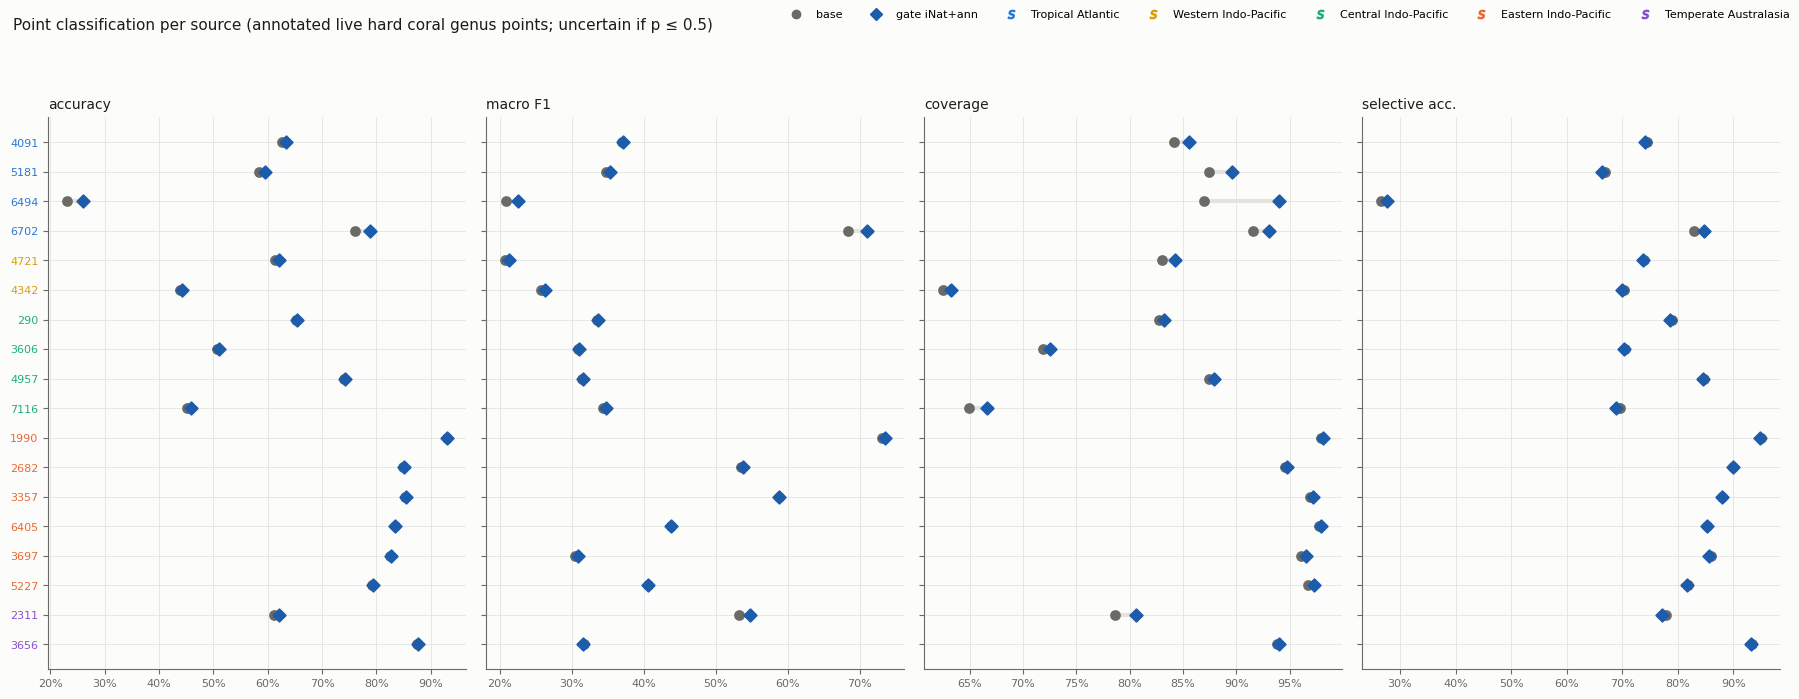

In [6]:
PLOT_METRICS = ["accuracy", "macro F1", "coverage", "selective acc."]
t = CLS["source"]
order = SOURCES[::-1]
fig, axes = plt.subplots(1, len(PLOT_METRICS), figsize=(18, 7), sharey=True)
y = np.arange(len(order))
for ax, k in zip(axes, PLOT_METRICS):
    for i, s in enumerate(order):
        vals = [t.loc[s, (k, m)] for m in METHODS]
        ax.plot([min(vals), max(vals)], [i, i], color=GRID, lw=3, zorder=1)
    for m in METHODS:
        c, mk, filled = M_STYLE[m]
        ax.scatter(t.loc[order, (k, m)], y, marker=mk, s=40, color=c if filled else SURFACE, edgecolor=c, lw=1.4,
                   zorder=3)
    ax.set_title(k)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
axes[0].set_yticks(y)
axes[0].set_yticklabels([str(s) for s in order])
for lab, s in zip(axes[0].get_yticklabels(), order):
    lab.set_color(REGION_COLOR[REGION_OF[s]])
handles = [Line2D([], [], marker=M_STYLE[m][1], color=M_STYLE[m][0], lw=0,
                  mfc=M_STYLE[m][0] if M_STYLE[m][2] else SURFACE, label=m) for m in METHODS]
handles += [Line2D([], [], lw=0, marker="$S$", color=c, label=r) for r, c in REGION_COLOR.items()]
fig.legend(handles=handles, loc="upper right", ncol=len(handles), fontsize=8)
fig.suptitle(f"Point classification per source (annotated live hard coral genus points; uncertain if p ≤ {THRESH})",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(OUT / "per_source_classification.png", dpi=150)
plt.show()

## 4. What changes: correct / wrong / uncertain, before vs after

Each annotated point is *correct*, *wrong* (another genus) or *uncertain* under `base` and under the gate. The
off-diagonal cells are what gating does: e.g. *wrong → correct* is a fix and *uncertain → correct* is a point
gating made confident and right.

In [7]:
def status(yh, y=None):
    y = Y if y is None else y
    return np.select([yh == UNC, yh == y], ["uncertain", "correct"], "wrong")


ST = ["correct", "wrong", "uncertain"]
for m in GATES:
    tab = pd.crosstab(pd.Series(status(YH["base"]), name="base"), pd.Series(status(YH[m]), name=m)).reindex(
        index=ST, columns=ST, fill_value=0)
    tab["total"] = tab.sum(axis=1)
    tab.loc["total"] = tab.sum()
    print(f"--- {m} (pooled) ---")
    display(tab)
    per = pd.DataFrame({r: pd.crosstab(status(YH["base"][rm := (E.region == r).to_numpy()], Y[rm]),
                                        status(YH[m][rm], Y[rm]))
                       .reindex(index=ST, columns=ST, fill_value=0).stack() for r in REGIONS}).T
    per.columns = [f"{a} → {b}" for a, b in per.columns]
    per = per[[c for c in per.columns if c.split(" → ")[0] != c.split(" → ")[1]]]
    print(f"--- {m}, changed points per realm ---")
    display(per)

--- gate iNat+ann (pooled) ---


gate iNat+ann,correct,wrong,uncertain,total
base,,,,
correct,53676,0,0,53676
wrong,35,13318,89,13442
uncertain,317,442,12141,12900
total,54028,13760,12230,80018


--- gate iNat+ann, changed points per realm ---


,correct → wrong,correct → uncertain,wrong → correct,wrong → uncertain,uncertain → correct,uncertain → wrong
Tropical Atlantic,0,0,32,34,89,106
Western Indo-Pacific,0,0,1,11,80,102
Central Indo-Pacific,0,0,1,21,90,140
Eastern Indo-Pacific,0,0,0,0,42,54
Temperate Australasia,0,0,1,23,16,40


### 4.1 Transition matrices: base label → gated label

Annotated live hard coral genus points whose label changes. Rows are the base label and columns the gated label.
`uncertain` is a label on both axes. Each cell shows the number of points, with the number now correct (✓)
underneath. Colour is the point count (log scale). Row labels give the realms the transitions occur in (pooled
matrices only) and the row total; column labels give the column total and the number now correct. Genera beyond
the top `TOP_N` per axis are pooled into *other*. The full, unpooled transitions are in `transitions.csv`.

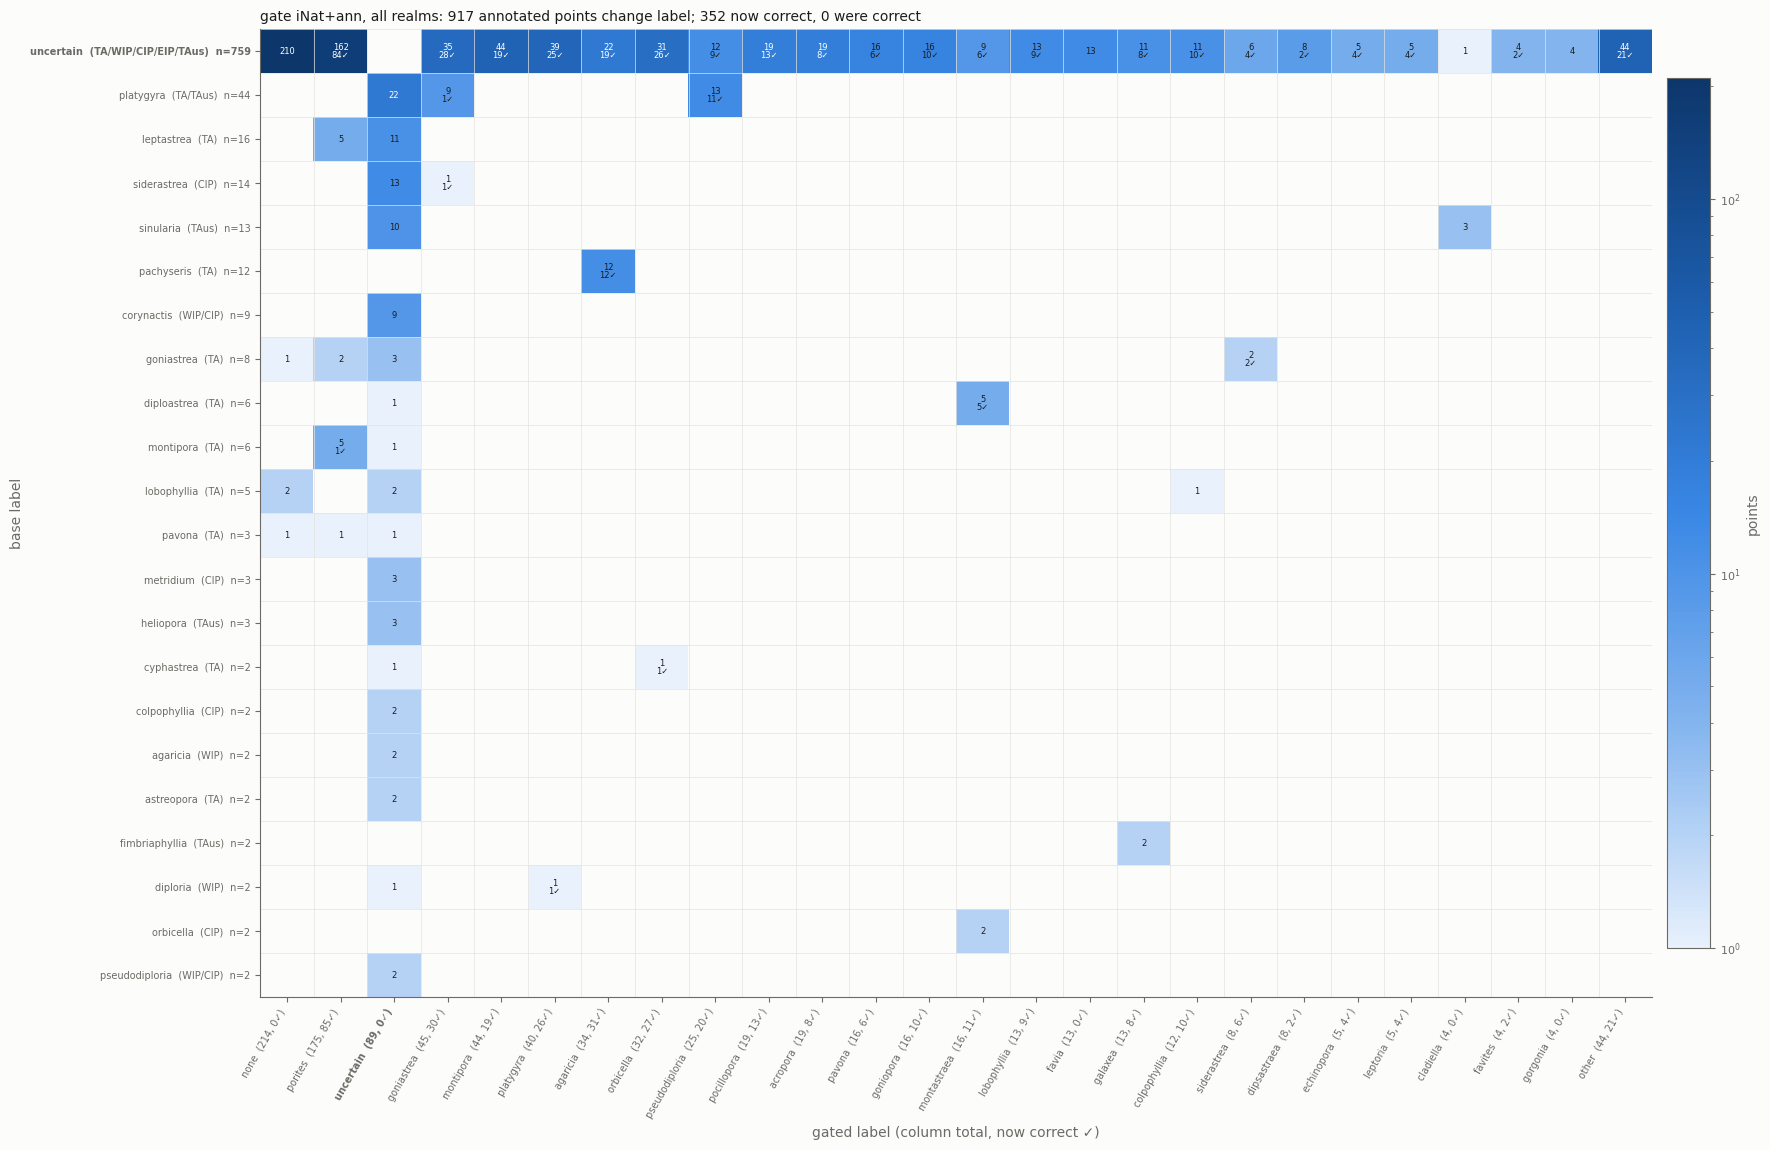

In [8]:
def transitions(m):
    ch = YH[m] != YH["base"]
    t = pd.DataFrame({"realm": E.region[ch].to_numpy(), "base": LABELS[YH["base"][ch]],
                      "gated": LABELS[YH[m][ch]], "truth": E.gt_genus[ch].to_numpy()})
    t["now correct"] = t.gated == t.truth
    t["was correct"] = t.base == t.truth
    return t


def plot_transitions(t, title, fname, show_realms):
    lump = lambda s, top: s.where(s.isin(top), "other")
    t2 = t.assign(base=lump(t.base, t.base.value_counts().index[:TOP_N]),
                  gated=lump(t.gated, t.gated.value_counts().index[:TOP_N]))
    n = pd.crosstab(t2.base, t2.gated)
    k = pd.crosstab(t2.base, t2.gated, values=t2["now correct"], aggfunc="sum").fillna(0).astype(int)
    ordr = lambda s: [x for x in s.sort_values(ascending=False).index if x != "other"] + (["other"] if "other" in s.index else [])
    r_ord, c_ord = ordr(n.sum(1)), ordr(n.sum(0))
    n, k = n.loc[r_ord, c_ord], k.loc[r_ord, c_ord]
    realms_of = t2.groupby("base").realm.agg(lambda s: "/".join(REALM_ABBR[r] for r in REGIONS if r in set(s)))
    ylab = [f"{g}  ({realms_of[g]})  n={int(n.loc[g].sum())}" if show_realms else f"{g}  n={int(n.loc[g].sum())}"
            for g in n.index]
    xlab = [f"{g}  ({int(n[g].sum())}, {int(k[g].sum())}✓)" for g in n.columns]
    M = n.to_numpy().astype(float)
    norm = LogNorm(vmin=1, vmax=max(M.max(), 2))
    fig, ax = plt.subplots(figsize=(0.5 * len(c_ord) + 4.8, 0.4 * len(r_ord) + 2.8))
    im = ax.imshow(np.where(M > 0, M, np.nan), cmap=SEQ, norm=norm, aspect="auto")
    for (a, b), v in np.ndenumerate(M):
        if v > 0:
            ax.text(b, a, f"{int(v)}\n{k.iat[a, b]}✓" if k.iat[a, b] else f"{int(v)}", ha="center", va="center",
                    fontsize=6, color="white" if norm(v) > 0.55 else INK, linespacing=0.9)
    ax.set_xticks(range(len(c_ord)))
    ax.set_xticklabels(xlab, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(r_ord)))
    ax.set_yticklabels(ylab, fontsize=7)
    for tl in ax.get_xticklabels() + ax.get_yticklabels():
        if tl.get_text().startswith("uncertain"):
            tl.set_fontweight("bold")
    ax.grid(False)
    ax.set_xticks(np.arange(-0.5, len(c_ord)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(r_ord)), minor=True)
    ax.grid(which="minor", color=GRID, lw=0.5)
    ax.tick_params(which="minor", length=0)
    ax.set_xlabel("gated label (column total, now correct ✓)")
    ax.set_ylabel("base label")
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01).set_label("points", color=MUTED)
    ax.set_title(title, fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=150)
    plt.show()


slug = lambda s: s.replace(" ", "_").replace("+", "plus").replace("-", "")
TRANS = {m: transitions(m) for m in GATES}
for m in GATES:
    t = TRANS[m]
    plot_transitions(t, f"{m}, all realms: {len(t):,} annotated points change label; "
                        f"{int(t['now correct'].sum()):,} now correct, {int(t['was correct'].sum()):,} were correct",
                     f"transition_matrix_{slug(m)}.png", show_realms=True)
full = (pd.concat(TRANS, names=["gate"]).reset_index(level=0)
        .groupby(["gate", "realm", "base", "gated"])
        .agg(points=("truth", "size"), now_correct=("now correct", "sum"), was_correct=("was correct", "sum"))
        .reset_index().sort_values(["gate", "points"], ascending=[True, False]))
full.to_csv(OUT / "transitions.csv", index=False)

### 4.2 Transition matrices per realm (`gate iNat+ann`)

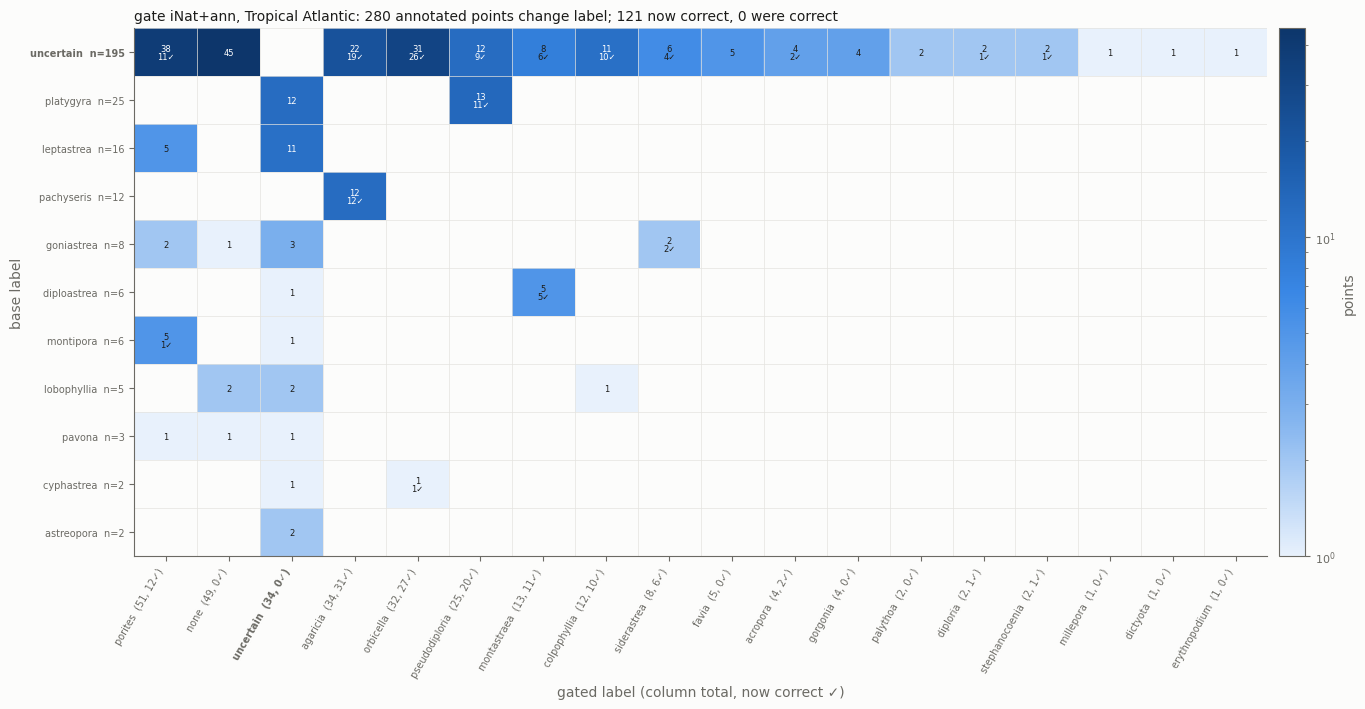

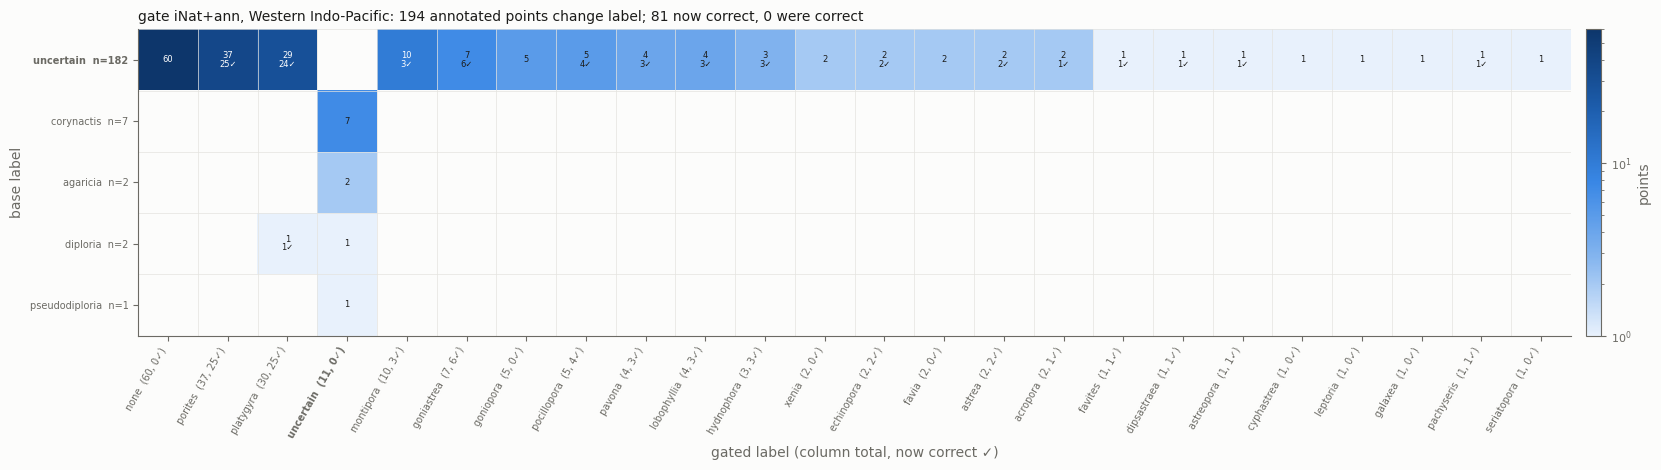

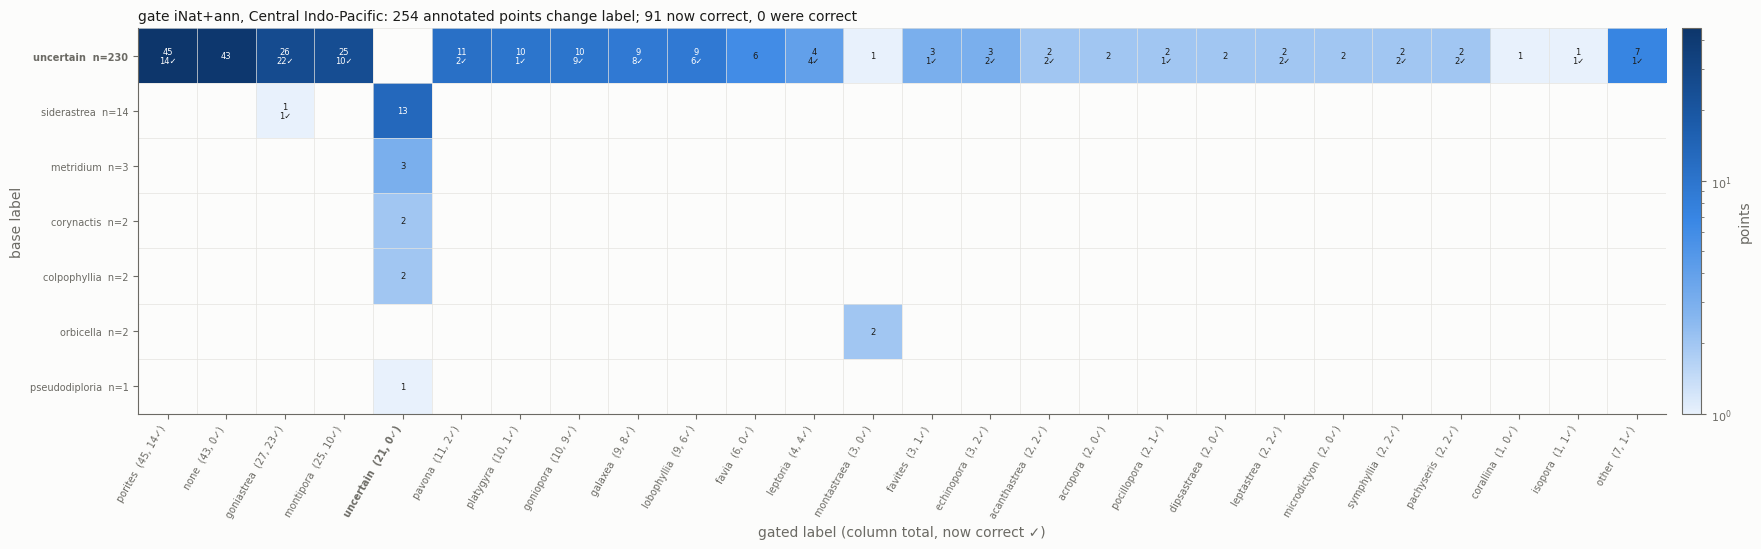

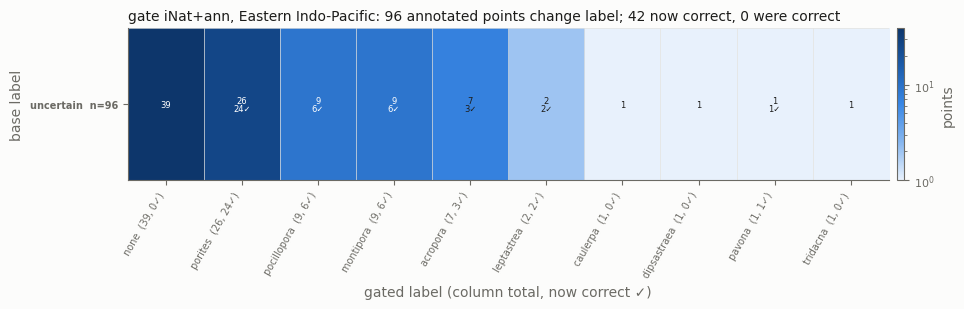

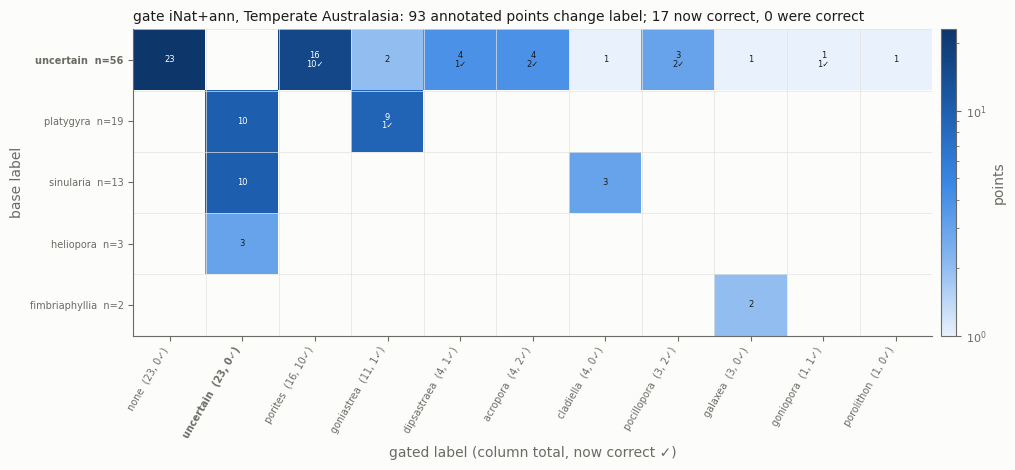

In [9]:
t = TRANS[MAIN]
for r in REGIONS:
    tr = t[t.realm == r]
    if len(tr) == 0:
        print(f"{r}: no annotated point changes label")
        continue
    plot_transitions(tr, f"{MAIN}, {r}: {len(tr):,} annotated points change label; "
                         f"{int(tr['now correct'].sum()):,} now correct, {int(tr['was correct'].sum()):,} were correct",
                     f"transition_matrix_{slug(MAIN)}_{slug(r)}.png", show_realms=False)

## 5. Per genus: who gains, who loses (`gate iNat+ann`)

Pooled over all test data. Gating helps a genus by stopping out-of-realm genera taking its points (its recall goes
up) and by stopping the genus itself being predicted where it doesn't occur (its precision goes up). With the
`uncertain` rule it can also raise recall by making a correct but under-confident prediction confident. It hurts a
genus annotated in a realm where the gate says the genus doesn't occur.

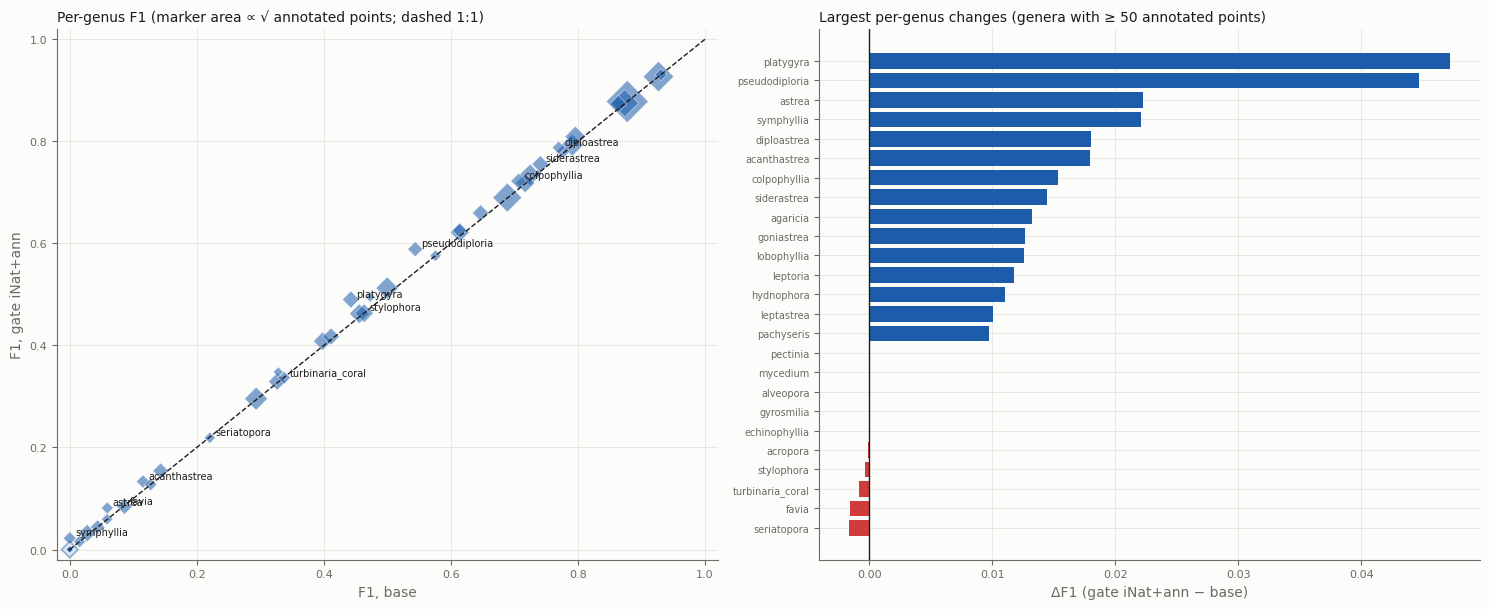

In [10]:
def per_genus(m):
    y, yh = Y, YH[m]
    sup, npred = np.bincount(y, minlength=NL), np.bincount(yh, minlength=NL)
    tp = np.bincount(y[y == yh], minlength=NL)
    with np.errstate(invalid="ignore", divide="ignore"):
        return pd.DataFrame({"support": sup, "precision": tp / npred, "recall": tp / sup,
                             "F1": 2 * tp / (sup + npred)}, index=LABELS)


PG = {m: per_genus(m) for m in METHODS}
pg = pd.concat({m: PG[m][["precision", "recall", "F1"]] for m in METHODS}, axis=1).swaplevel(axis=1)
pg.insert(0, ("support", ""), PG["base"].support)
pg = pg[pg[("support", "")] > 0].sort_values(("support", ""), ascending=False)
SUP = pg[("support", "")]
for m in METHODS[1:]:
    pg[("ΔF1", m)] = pg[("F1", m)] - pg[("F1", "base")]
pg.to_csv(OUT / "per_genus.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
ax = axes[0]
c, mk, _ = M_STYLE[MAIN]
ax.scatter(pg[("F1", "base")], pg[("F1", MAIN)], s=10 + 2.5 * np.sqrt(SUP), marker=mk, color=c, alpha=0.55,
           edgecolor="white", lw=0.5)
ax.plot([0, 1], [0, 1], color=INK, lw=1, ls="--")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("F1, base")
ax.set_ylabel(f"F1, {MAIN}")
ax.set_title("Per-genus F1 (marker area ∝ √ annotated points; dashed 1:1)")
big = pg[SUP >= 50]
d = big[("ΔF1", MAIN)]
for g in set(d.nlargest(8).index) | set(d.nsmallest(4).index):
    ax.annotate(g, (pg.loc[g, ("F1", "base")], pg.loc[g, ("F1", MAIN)]), xytext=(4, 2),
                textcoords="offset points", fontsize=7, color=INK)
ax = axes[1]
top = d.sort_values()
top = pd.concat([top.head(10), top.tail(15)])
top = top[~top.index.duplicated()]
ax.barh(top.index, top.values, color=[M_STYLE[MAIN][0] if v >= 0 else "#d03b3b" for v in top.values])
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel(f"ΔF1 ({MAIN} − base)")
ax.set_title("Largest per-genus changes (genera with ≥ 50 annotated points)")
ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
fig.savefig(OUT / "per_genus_f1.png", dpi=150)
plt.show()
cols = [("support", "")] + [("F1", m) for m in METHODS] + [("ΔF1", m) for m in METHODS[1:]]
display(pg.loc[SUP >= 50, cols].head(30).style.format("{:.3f}", subset=cols[1:]))

## 6. Calibration of the (renormalized) top probability

Accuracy of the raw argmax against its probability, pooled. The dotted line marks `THRESH`: points to its left
become `uncertain`. Renormalizing raises the confidence of gated predictions, so this checks whether that higher
confidence is earned and whether 0.5 is a sensible cut.

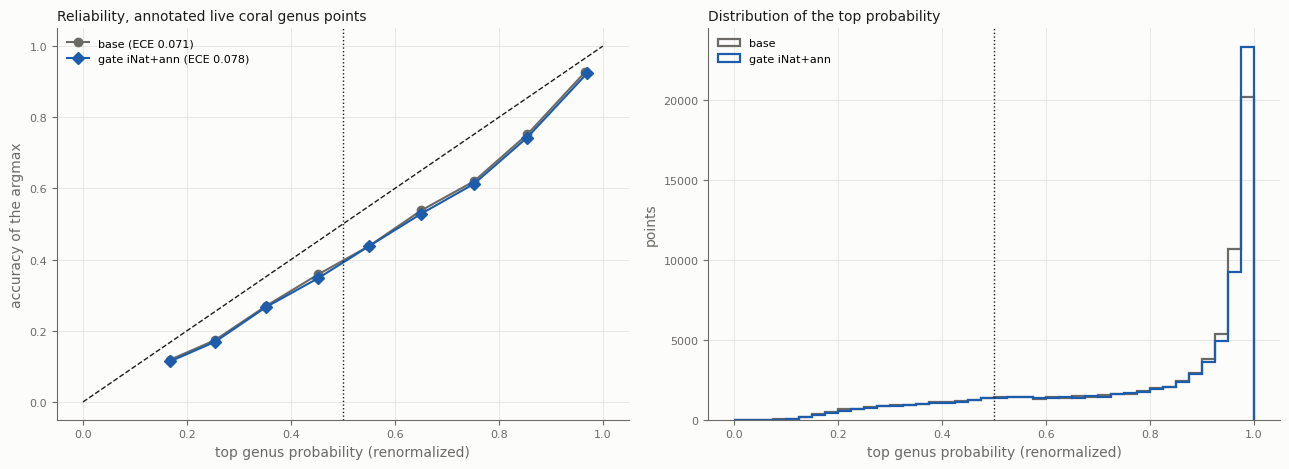

In [11]:
bins = np.linspace(0, 1, 11)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
for m in METHODS:
    c, mk, _ = M_STYLE[m]
    conf, corr = CONF[m][E_idx], RAW[m][E_idx] == Y
    b = np.clip(np.digitize(conf, bins) - 1, 0, 9)
    df = (pd.DataFrame({"b": b, "conf": conf, "corr": corr}).groupby("b")
          .agg(conf=("conf", "mean"), acc=("corr", "mean"), n=("corr", "size")))
    df = df[df.n >= 50]
    ece = (np.abs(df.conf - df.acc) * df.n).sum() / len(conf)
    ax.plot(df.conf, df.acc, marker=mk, color=c, label=f"{m} (ECE {ece:.3f})")
    axes[1].hist(conf, bins=np.linspace(0, 1, 41), histtype="step", color=c, lw=1.6, label=m)
ax.plot([0, 1], [0, 1], color=INK, lw=1, ls="--")
for a_ in axes:
    a_.axvline(THRESH, color=INK, lw=1, ls=":")
ax.set_xlabel("top genus probability (renormalized)")
ax.set_ylabel("accuracy of the argmax")
ax.set_title("Reliability, annotated live coral genus points")
ax.legend(fontsize=8)
axes[1].set_xlabel("top genus probability (renormalized)")
axes[1].set_ylabel("points")
axes[1].set_title("Distribution of the top probability")
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

## 7. Diversity: base vs gated, at the points and on all pixels

The analysis of `nbs/Coral_Taxon_Diversity_Live_CD275k_Res768_Regions.ipynb`, done for both the base and the gated model.
Live hard coral and the genus rule are as in sections 2–3: a point or pixel counts if it is predicted live hard coral
(order head = scleractinia, P(live) > 0.5) and its label is a hard coral genus. `uncertain` labels (p ≤ `THRESH`)
add no genus.

**Presence of a genus in an image.**
- **Ground truth**: at least one annotated live coral point of the genus.
- **Model at the points**: at least one annotated point predicted live coral of the genus (all points of the image).
- **Model, all pixels**: at least **`TAU` = 1%** of the image's pixels predicted live coral of the genus. Gating is
  applied per pixel (`inat/gating_dense_predict.py`).

**Diversity measures**, from a set of images:
- **Richness**: the number of genera present.
- **Effective number**: Hill number of order 1 (exp Shannon) of the summed abundances: point counts, or pixel shares
  of the genera passing `TAU`.
- **Genus-list precision / recall**: the share of the model's genera that are annotated / of annotated genera found.
- **Composition similarity**: 1 − Bray–Curtis on relative abundances.

Bootstrap CIs resample images. Accumulation curves draw `R` random image orders.

In [12]:
TAU = 0.01
R = 300
N_GRID = [5, 10, 25, 50, 100, 250, 500, 1000, 2500, 5000, 10_000, 25_000]
ESTIMATES = {  # key -> (label, colour, linestyle, marker filled)
    "truth": ("ground truth (points)", INK, "-", True),
    "base_points": ("base, at the points", M_STYLE["base"][0], ":", True),
    "gate_points": ("gated, at the points", M_STYLE[MAIN][0], ":", True),
    "base_dense": (f"base, all pixels (≥{TAU:.0%})", M_STYLE["base"][0], "-", False),
    "gate_dense": (f"gated, all pixels (≥{TAU:.0%})", M_STYLE[MAIN][0], "-", False),
}
MODEL_KEYS = [k for k in ESTIMATES if k != "truth"]
PAIRS = {"at the points": ("base_points", "gate_points"), "all pixels": ("base_dense", "gate_dense")}

dense = pd.read_parquet(GATE_DIR / "dense.parquet")
dimg = (pd.read_parquet(GATE_DIR / "dense_images.parquet").sort_values(["source_id", "image_id"])
        .reset_index(drop=True))
assert set(dimg.source_id) == set(SOURCES)

# Check: the ungated plain argmax reproduces KL05's all-pixel shares.
kd = pd.read_parquet(str(KL05).replace(".parquet", "_dense.parquet"))
kd = kd[(kd.level == "genus") & kd.source_id.isin(SOURCES)]
mine = dense[dense.variant == "base_argmax"]
cmp_ = kd.assign(taxon=kd.taxon.astype(str)).merge(mine.assign(taxon=mine.taxon.astype(str)),
                                                    on=["source_id", "image_id", "taxon"], how="outer", suffixes=("_kl", ""))
cmp_[["share", "share_kl"]] = cmp_[["share", "share_kl"]].fillna(0)
print(f"base plain argmax vs KL05 all-pixel genus shares: {len(cmp_):,} (image, genus) rows, "
      f"max |Δshare| = {np.abs(cmp_.share - cmp_.share_kl).max():.2e}")

T_COL = {t: j for j, t in enumerate(TAXA)}
img_key = dimg[["source_id", "image_id"]].assign(r=np.arange(len(dimg)))
row_of = lambda df: df[["source_id", "image_id"]].merge(img_key, how="left", on=["source_id", "image_id"]).r.to_numpy()
pt_row = row_of(pts)
assert not np.isnan(pt_row.astype(float)).any()


def point_matrix(mask, label_idx):
    # (images × taxa) point counts of the hard coral genus labels selected by mask
    lab = LABELS[label_idx[mask]]
    c = pd.DataFrame({"r": pt_row[mask], "c": pd.Series(lab).map(T_COL).to_numpy()}).dropna().astype(int).value_counts()
    a = np.zeros((len(dimg), len(TAXA)), dtype=np.float32)
    a[c.index.get_level_values(0), c.index.get_level_values(1)] = c.to_numpy()
    return a


def dense_matrix(variant):
    d = dense[(dense.variant == variant) & dense.taxon.isin(T_COL)]
    a = np.zeros((len(dimg), len(TAXA)), dtype=np.float32)
    a[row_of(d), d.taxon.astype(str).map(T_COL).to_numpy()] = d.share.to_numpy()
    return a


GT_LAB = pts.gt_genus.map(L_IDX).fillna(UNC).astype(int).to_numpy()  # UNC where no genus label
MAT = {"truth": point_matrix(ev, GT_LAB),
       "base_points": point_matrix(pts.pred_live.to_numpy() & IS_SCLER[PRED["base"]], PRED["base"]),
       "gate_points": point_matrix(pts.pred_live.to_numpy() & IS_SCLER[PRED[MAIN]], PRED[MAIN]),
       "base_dense": dense_matrix("base_thresh"), "gate_dense": dense_matrix("gate_thresh")}


def abundance(rows, key, tau=TAU):
    a = MAT[key][rows]
    return np.where(a >= tau, a, 0.0) if key.endswith("_dense") else a


def hill1(s):
    total = s.sum(axis=-1, keepdims=True)
    p = np.divide(s, total, out=np.zeros_like(s, dtype=np.float64), where=total > 0)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.nansum(np.where(p > 0, p * np.log(p), 0.0), axis=-1)
    return np.exp(h)


src_d = dimg.source_id.to_numpy()
reg_d = dimg.source_id.map(REGION_OF).to_numpy()
DROWS = {"source": {s: np.flatnonzero(src_d == s) for s in SOURCES},
         "realm": {r: np.flatnonzero(reg_d == r) for r in REGIONS},
         "all": {"all test": np.arange(len(dimg))}}
print(f"{len(dimg):,} images; live coral pixels labelled uncertain (share of live coral pixels, pooled): "
      f"base {dimg.unc_base_thresh.sum() / dimg.dense_live.sum():.1%}, "
      f"gated {dimg.unc_gate_thresh.sum() / dimg.dense_live.sum():.1%}")

base plain argmax vs KL05 all-pixel genus shares: 121,293 (image, genus) rows, max |Δshare| = 4.24e-05


24,051 images; live coral pixels labelled uncertain (share of live coral pixels, pooled): base 18.3%, gated 17.5%


### 7.1 Summary per source, per realm, pooled

Richness, effective number (95% bootstrap CI) and the genus-list and composition measures of each estimate.

In [13]:
def summarize(scope):
    res = {}
    for g, rows in DROWS[scope].items():
        gt_sum = abundance(rows, "truth").sum(axis=0)
        gt_present, gt_rel = gt_sum > 0, gt_sum / gt_sum.sum()
        w = rng.multinomial(len(rows), np.full(len(rows), 1 / len(rows)), size=B).astype(np.float32)  # paired
        r = {}
        for key in ESTIMATES:
            a = abundance(rows, key)
            s = a.sum(axis=0)
            present = s > 0
            boot = hill1(w @ a)
            rel = s / s.sum() if s.sum() > 0 else np.zeros_like(gt_rel)
            r[key] = {"richness": int(present.sum()), "effective": float(hill1(s)),
                      "eff lo": np.quantile(boot, 0.025), "eff hi": np.quantile(boot, 0.975),
                      "precision": (present & gt_present).sum() / max(present.sum(), 1),
                      "recall": (present & gt_present).sum() / gt_present.sum(),
                      "composition similarity": 1 - np.abs(rel - gt_rel).sum() / 2}
        res[g] = r
    t = pd.concat({g: pd.DataFrame(r).T for g, r in res.items()}, names=["group", "estimate"]).unstack("estimate")
    t["images"] = [len(DROWS[scope][g]) for g in t.index]
    return t


def show_summary(t):
    out = pd.DataFrame(index=t.index)
    out["images"] = t.images
    for k in ESTIMATES:
        out[("richness", ESTIMATES[k][0])] = t[("richness", k)].astype(int)
    for k in ESTIMATES:
        out[("effective", ESTIMATES[k][0])] = [f"{v:.1f} [{lo:.1f}, {hi:.1f}]" for v, lo, hi in
                                               zip(t[("effective", k)], t[("eff lo", k)], t[("eff hi", k)])]
    for m in ("precision", "recall", "composition similarity"):
        for k in MODEL_KEYS:
            out[(m, ESTIMATES[k][0])] = t[(m, k)].astype(float).round(2)
    out.columns = pd.MultiIndex.from_tuples([c if isinstance(c, tuple) else (c, "") for c in out.columns])
    return out


DSUM = {scope: summarize(scope) for scope in DROWS}
pd.concat({s: show_summary(t) for s, t in DSUM.items()}, names=["scope"]).to_csv(OUT / "diversity_summary.csv")
for scope in ("all", "realm", "source"):
    print(f"--- per {scope} ---")
    display(show_summary(DSUM[scope]))

--- per all ---


images              richness                                                                                                     effective                                                                                          \
                ground truth (points) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%) ground truth (points) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%)   
group                                                                                                                                                                                                                                         
all test  24051                    76                  45                   44                     46                      47     12.3 [11.9, 12.7]      7.8 [7.6, 8.0]       7.8 [7.6, 8.0]         7.7 [7.5, 7.9]          7.7 [7.5, 7.9]   

                   precision                                                                                  recall                                                                     composition similarity                       \
         base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%)    base, at the points gated, at the points   
group                                                                                                                                                                                                                                  
all test                0.98                  1.0                   0.98                     1.0                0.58                 0.58                   0.59                    0.62                   0.86                 0.86   

                                                         
         base, all pixels (≥1%) gated, all pixels (≥1%)  
group                                                    
all test                   0.84                    0.84

--- per realm ---


images              richness                                                                                                     effective                                                                  \
                             ground truth (points) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%) ground truth (points) base, at the points gated, at the points base, all pixels (≥1%)   
group                                                                                                                                                                                                                              
Tropical Atlantic       3025                    23                  26                   14                     30                      14        7.7 [7.3, 8.0]      7.8 [7.4, 8.2]       7.2 [6.9, 7.5]         8.2 [7.7, 8.5]   
Western Indo-Pacific    3373                    46                  38                   33                     36                      32     13.1 [12.4, 13.6]      6.2 [5.9, 6.5]       6.2 [5.9, 6.5]         5.4 [5.1, 5.6]   
Central Indo-Pacific   12194                    50                  38                   34                     41                      37     14.9 [14.4, 15.3]   10.7 [10.3, 11.1]    10.7 [10.3, 11.1]         7.7 [7.4, 8.0]   
Eastern Indo-Pacific    4988                    18                  12                   14                     10                      10        2.8 [2.6, 2.9]      2.6 [2.5, 2.8]       2.6 [2.5, 2.8]         2.5 [2.4, 2.6]   
Temperate Australasia    471                    11                  19                   16                     18                      14        2.6 [2.3, 3.0]      2.4 [2.0, 2.8]       2.1 [1.8, 2.4]         2.1 [1.8, 2.3]   

                                                        precision                                                                                  recall                                                                      \
                      gated, all pixels (≥1%) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%)   
group                                                                                                                                                                                                                           
Tropical Atlantic              7.5 [7.1, 7.7]                0.54                 1.00                   0.43                    1.00                0.61                 0.61                   0.57                    0.61   
Western Indo-Pacific           5.4 [5.1, 5.6]                0.76                 0.88                   0.78                    0.88                0.63                 0.63                   0.61                    0.61   
Central Indo-Pacific           7.7 [7.4, 8.0]                0.89                 1.00                   0.83                    0.97                0.68                 0.68                   0.68                    0.72   
Eastern Indo-Pacific           2.5 [2.4, 2.6]                0.83                 0.71                   0.80                    0.80                0.56                 0.56                   0.44                    0.44   
Temperate Australasia          2.0 [1.8, 2.2]                0.42                 0.50                   0.44                    0.57                0.73                 0.73                   0.73                    0.73   

                      composition similarity                                                                      
                         base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%)  
group                                                                                                             
Tropical Atlantic                       0.92       

--- per source ---


images              richness                                                                                                     effective                                                                                          \
             ground truth (points) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%) ground truth (points) base, at the points gated, at the points base, all pixels (≥1%) gated, all pixels (≥1%)   
group                                                                                                                                                                                                                                      
4091     463                    15                  14                   12                     14                      12        5.5 [5.1, 5.8]      5.2 [4.7, 5.5]       5.1 [4.7, 5.4]         5.0 [4.6, 5.2]          4.9 [4.6, 5.2]   
5181    1061                    20                  18                   13                     19                      13        7.3 [6.7, 7.7]      6.6 [5.9, 7.2]       6.5 [5.8, 7.0]         6.3 [5.7, 6.9]          6.2 [5.6, 6.7]   
6494     133                     9                  10                    7                     10                       8        4.7 [3.8, 5.5]      4.8 [3.2, 5.9]       4.5 [3.2, 5.5]         4.6 [3.3, 5.6]          4.4 [3.2, 5.3]   
6702    1368                    12                  22                   12                     27                      12        6.7 [6.3, 7.0]      7.7 [7.0, 8.2]       6.8 [6.3, 7.0]         7.4 [6.8, 7.8]          6.7 [6.2, 6.9]   
4721    2909                    34                  34                   29                     33                      29        8.2 [7.6, 8.7]      4.5 [4.3, 4.7]       4.5 [4.3, 4.7]         4.2 [4.0, 4.4]          4.2 [4.0, 4.4]   
4342     464                    37                  29                   28                     26                      25     13.6 [12.6, 14.4]      8.4 [7.7, 9.0]       8.5 [7.8, 9.1]         7.1 [6.5, 7.6]          7.2 [6.6, 7.7]   
290      227                    22                  17                   17                     23                      22        7.7 [6.1, 8.7]      6.0 [4.9, 6.8]       6.0 [4.9, 6.8]         5.3 [4.5, 6.0]          5.3 [4.5, 6.0]   
3606    2185                    32                  29                   29                     32                      30     12.8 [12.1, 13.3]      9.1 [8.6, 9.4]       9.1 [8.6, 9.4]         8.7 [8.3, 9.1]          8.7 [8.3, 9.1]   
4957    9012                    41                  32                   30                     38                      34        6.6 [6.2, 6.9]      5.6 [5.4, 5.9]       5.6 [5.4, 5.9]         5.5 [5.2, 5.7]          5.5 [5.2, 5.7]   
7116     770                    18                  24                   22                     16                      17      10.3 [9.7, 10.8]      7.7 [7.0, 8.3]       7.6 [6.9, 8.2]         4.2 [3.7, 4.6]          4.2 [3.7, 4.7]   
1990    1233                     4                   6                    6                      7                       7        1.9 [1.8, 2.0]      1.8 [1.7, 1.9]       1.8 [1.7, 1.9]         1.7 [1.7, 1.8]          1.7 [1.7, 1.8]   
2682     675                     5                   8                    9                      7                       7        2.4 [2.2, 2.5]      2.1 [1.9, 2.2]       2.1 [1.9, 2.2]         2.0 [1.9, 2.2]          2.0 [1.9, 2.2]   
3357     564                     6                   6                    6                      7                       7        2.3 [2.1, 2.4]      2.1 [1.9, 2.3]       2.1 [1.9, 2.3]         2.1 [1.9, 2.3]          2.1 [1.9, 2.3]   
6405    1332                     7                   6                    6                      8                       8        2.9 [2.6, 3.2]      2.7 [2.4, 2.9]       2.7 [2.4, 2.9]         2.6 [2.4, 2.8]          2.6 [2.4, 2.

Change from base to gated per source (arrow from base to gated; colour = realm). Left: richness against the annotated
richness (dashed 1:1). Middle: effective number. Right: genus-list precision against recall, so an arrow pointing up
is a list with fewer false genera and an arrow pointing left is lost genera. Top row: at the points; bottom row: all
pixels.

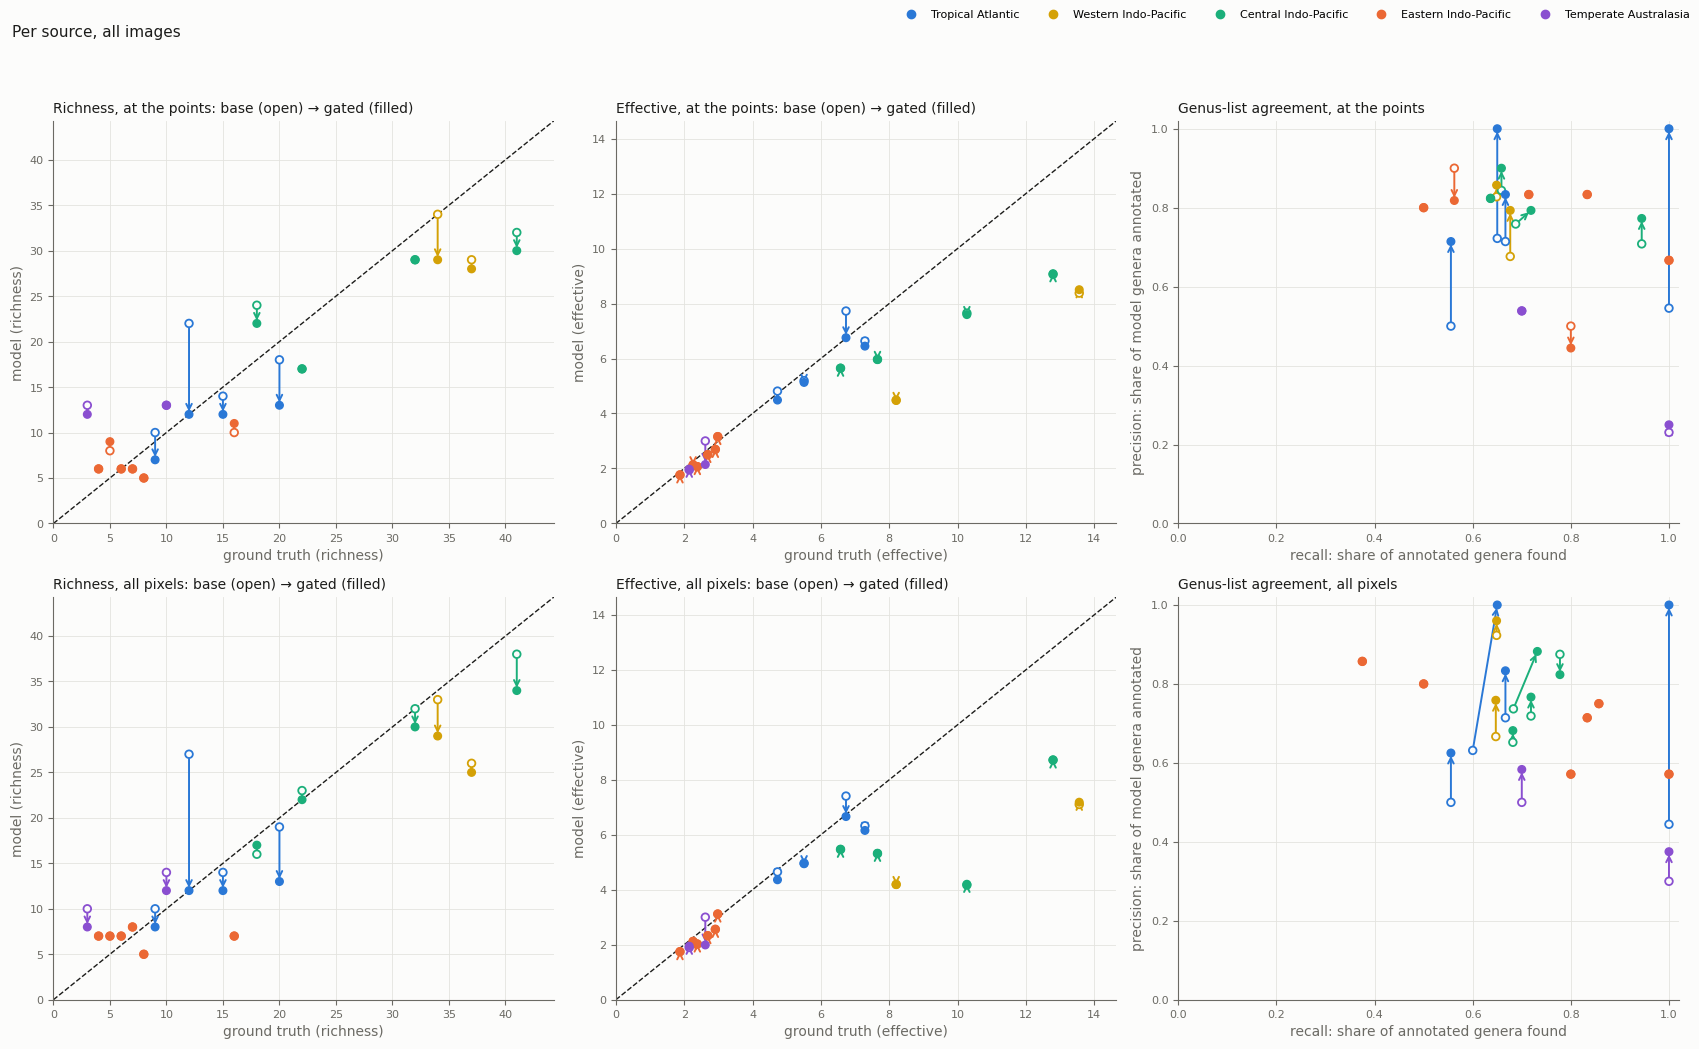

In [14]:
t = DSUM["source"]
colors = [REGION_COLOR[REGION_OF[s]] for s in t.index]
fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
for i, (where, (kb, kg)) in enumerate(PAIRS.items()):
    for j, metric in enumerate(("richness", "effective")):
        ax = axes[i, j]
        gt = t[(metric, "truth")].astype(float)
        yb, yg = t[(metric, kb)].astype(float), t[(metric, kg)].astype(float)
        for x, a, b, c in zip(gt, yb, yg, colors):
            ax.annotate("", (x, b), (x, a), arrowprops=dict(arrowstyle="->", color=c, lw=1.4))
        ax.scatter(gt, yb, s=30, facecolor=SURFACE, edgecolor=colors, lw=1.3, zorder=3)
        ax.scatter(gt, yg, s=30, c=colors, zorder=3)
        top = max(gt.max(), yb.max(), yg.max()) * 1.08
        ax.plot([0, top], [0, top], color=INK, lw=1, ls="--")
        ax.set_xlim(0, top)
        ax.set_ylim(0, top)
        ax.set_xlabel(f"ground truth ({metric})")
        ax.set_ylabel(f"model ({metric})")
        ax.set_title(f"{metric.capitalize()}, {where}: base (open) → gated (filled)")
    ax = axes[i, 2]
    for xa, ya, xb, yb_, c in zip(t[("recall", kb)], t[("precision", kb)], t[("recall", kg)], t[("precision", kg)], colors):
        ax.annotate("", (xb, yb_), (xa, ya), arrowprops=dict(arrowstyle="->", color=c, lw=1.4))
    ax.scatter(t[("recall", kb)], t[("precision", kb)], s=30, facecolor=SURFACE, edgecolor=colors, lw=1.3, zorder=3)
    ax.scatter(t[("recall", kg)], t[("precision", kg)], s=30, c=colors, zorder=3)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("recall: share of annotated genera found")
    ax.set_ylabel("precision: share of model genera annotated")
    ax.set_title(f"Genus-list agreement, {where}")
handles = [Line2D([], [], marker="o", color=c, lw=0, label=r) for r, c in REGION_COLOR.items()]
fig.legend(handles=handles, loc="upper right", ncol=len(handles), fontsize=8)
fig.suptitle("Per source, all images", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(OUT / "diversity_per_source_arrows.png", dpi=150)
plt.show()

Pooled over each realm and over all test data: the change from base to gated in each measure (gated − base), at the
points and on all pixels. *Richness error* is model richness − annotated richness, so a move towards 0 is better.

In [15]:
rows = []
for scope in ("realm", "all"):
    t = DSUM[scope]
    for g in t.index:
        for where, (kb, kg) in PAIRS.items():
            gt_r = t.loc[g, ("richness", "truth")]
            rows.append({"group": g, "estimate": where,
                         "richness error base": int(t.loc[g, ("richness", kb)] - gt_r),
                         "richness error gated": int(t.loc[g, ("richness", kg)] - gt_r),
                         **{f"Δ {m}": float(t.loc[g, (m, kg)] - t.loc[g, (m, kb)])
                            for m in ("effective", "precision", "recall", "composition similarity")}})
DDELTA = pd.DataFrame(rows).set_index(["group", "estimate"])
DDELTA.to_csv(OUT / "diversity_delta.csv")
DDELTA.style.format("{:+.2f}", subset=[c for c in DDELTA.columns if c.startswith("Δ")])

### 7.2 Accumulation: genera found after n images

Per realm and pooled: richness and recall after n random images (median and 95% band over `R` random orders;
dashed: annotated richness from all images, or 100% recall). The same orders are used for every estimate.

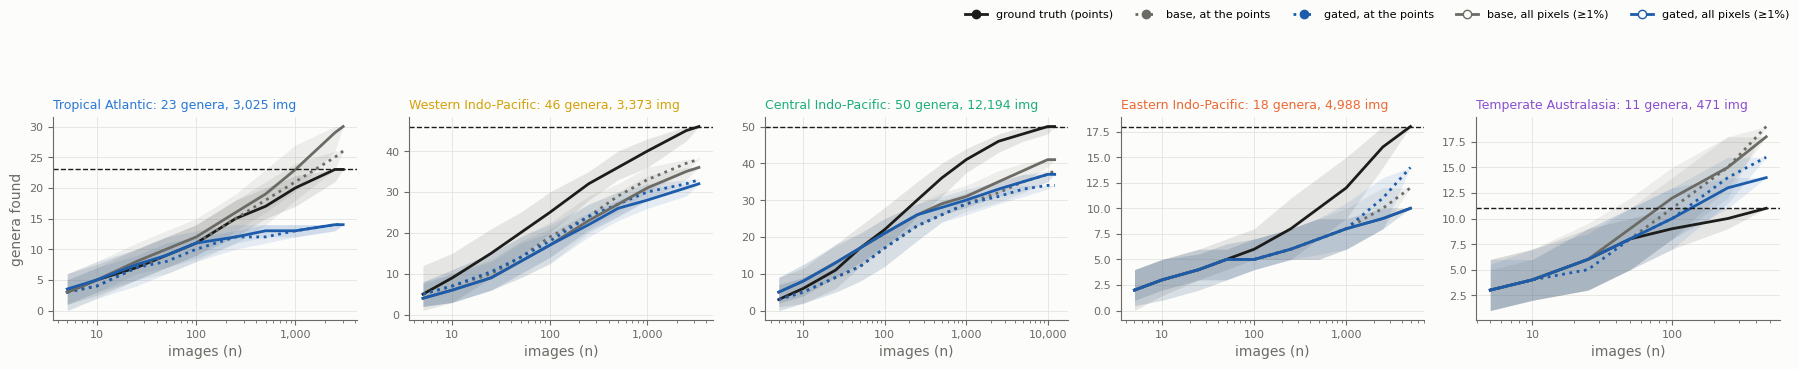

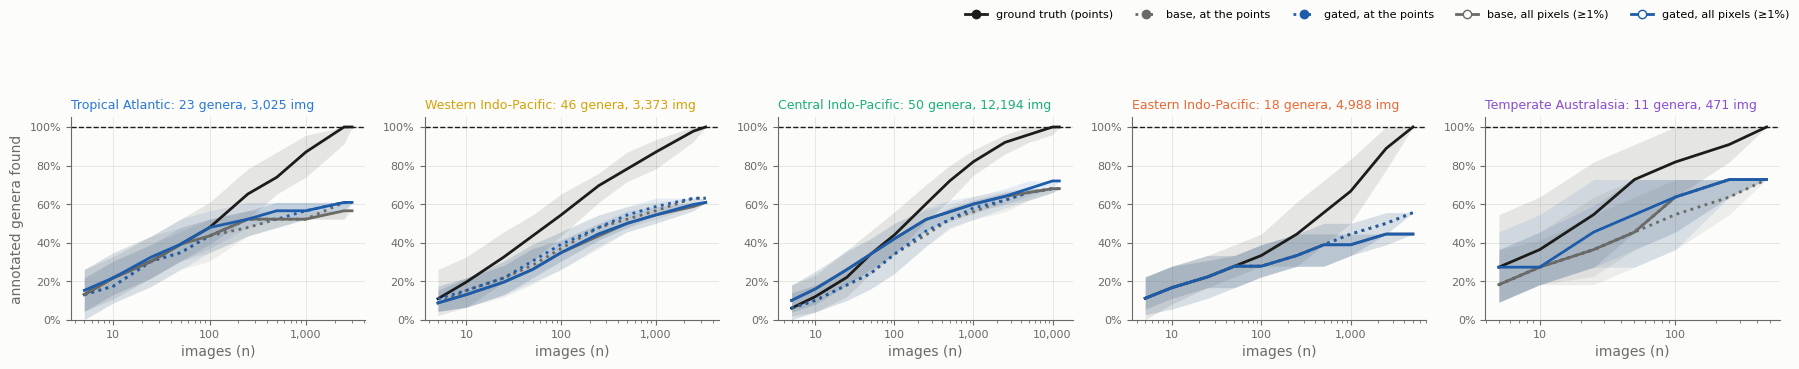

In [16]:
def accumulation(rows, keys=tuple(ESTIMATES)):
    n_all = len(rows)
    grid = [n for n in N_GRID if n < n_all] + [n_all]
    ranks = np.argsort(np.argsort(rng.random((R, n_all)), axis=1), axis=1)
    gt_present = abundance(rows, "truth").sum(axis=0) > 0
    out = []
    for key in keys:
        present = abundance(rows, key) > 0
        first = np.full((R, present.shape[1]), np.inf)
        for j in np.flatnonzero(present.any(axis=0)):
            first[:, j] = ranks[:, present[:, j]].min(axis=1)
        for n in grid:
            found = first < n
            rich = found.sum(axis=1)
            rec = (found & gt_present).sum(axis=1) / gt_present.sum()
            q, rq = np.quantile(rich, [0.025, 0.5, 0.975]), np.quantile(rec, [0.025, 0.5, 0.975])
            out.append({"n": n, "estimate": key, "rich lo": q[0], "rich": q[1], "rich hi": q[2],
                        "recall lo": rq[0], "recall": rq[1], "recall hi": rq[2]})
    return pd.DataFrame(out)


def hill_curve(rows):
    n_all = len(rows)
    ab = {k: abundance(rows, k).astype(np.float32) for k in ESTIMATES}
    out = []
    for n in [m for m in N_GRID if m < n_all] + [n_all]:
        w = np.zeros((R, n_all), dtype=np.float32)
        np.put_along_axis(w, np.argsort(rng.random((R, n_all)), axis=1)[:, :n], 1.0, axis=1)
        for k in ESTIMATES:
            q = np.quantile(hill1(w @ ab[k]), [0.025, 0.5, 0.975])
            out.append({"n": n, "estimate": k, "lo": q[0], "median": q[1], "hi": q[2]})
    return pd.DataFrame(out)


def legend(fig, keys=ESTIMATES):
    handles = [Line2D([], [], color=ESTIMATES[k][1], ls=ESTIMATES[k][2], lw=2, marker="o",
                      mfc=ESTIMATES[k][1] if ESTIMATES[k][3] else SURFACE, mec=ESTIMATES[k][1], label=ESTIMATES[k][0])
               for k in keys]
    fig.legend(handles=handles, loc="upper right", ncol=len(handles), fontsize=8)


def grid_plot(curves, scope, kind, ncols, panel=(3.6, 2.9), keys=tuple(ESTIMATES), fname=None):
    groups = list(curves)
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel[0] * ncols, panel[1] * nrows + 0.8), squeeze=False)
    s_all = DSUM[scope]
    for ax, g in zip(axes.flat, groups):
        c0 = curves[g]
        for key in keys:
            _, color, ls, _ = ESTIMATES[key]
            c = c0[c0.estimate == key]
            lo, mid, hi = ("lo", "median", "hi") if kind == "hill" else (f"{kind} lo", kind, f"{kind} hi")
            ax.fill_between(c.n, c[lo], c[hi], color=color, alpha=0.10, lw=0)
            ax.plot(c.n, c[mid], color=color, ls=ls, lw=2)
        s = s_all.loc[g]
        if kind == "rich":
            ax.axhline(s[("richness", "truth")], color=INK, lw=1, ls="--")
        elif kind == "recall":
            ax.axhline(1, color=INK, lw=1, ls="--")
            ax.set_ylim(0, 1.05)
            ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
        else:
            ax.axhline(s[("effective", "truth")], color=INK, lw=1, ls="--")
            ax.set_ylim(bottom=0)
        ax.set_xscale("log")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{int(v):,}"))
        ax.set_title(f"{g}: {int(s[('richness', 'truth')])} genera, {int(s['images'].iloc[0]) if hasattr(s['images'], 'iloc') else int(s['images']):,} img",
                     fontsize=9, color=REGION_COLOR.get(g, INK))
    for ax in axes.flat[len(groups):]:
        ax.axis("off")
    ylab = {"rich": "genera found", "recall": "annotated genera found", "hill": "effective number of genera"}[kind]
    for ax in axes[:, 0]:
        ax.set_ylabel(ylab)
    for ax in axes[-1]:
        ax.set_xlabel("images (n)")
    legend(fig, keys)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.8 / (panel[1] * nrows + 0.8)))
    if fname:
        fig.savefig(OUT / fname, dpi=150)
    plt.show()


ACC = {g: accumulation(rows) for g, rows in {**DROWS["realm"], **DROWS["all"]}.items()}
HILL = {g: hill_curve(rows) for g, rows in {**DROWS["realm"], **DROWS["all"]}.items()}
ACC_R = {g: ACC[g] for g in REGIONS}
grid_plot(ACC_R, "realm", "rich", ncols=len(REGIONS), fname="accumulation_richness_realm.png")
grid_plot(ACC_R, "realm", "recall", ncols=len(REGIONS), fname="accumulation_recall_realm.png")

All test data pooled, and the effective number from n random images per realm.

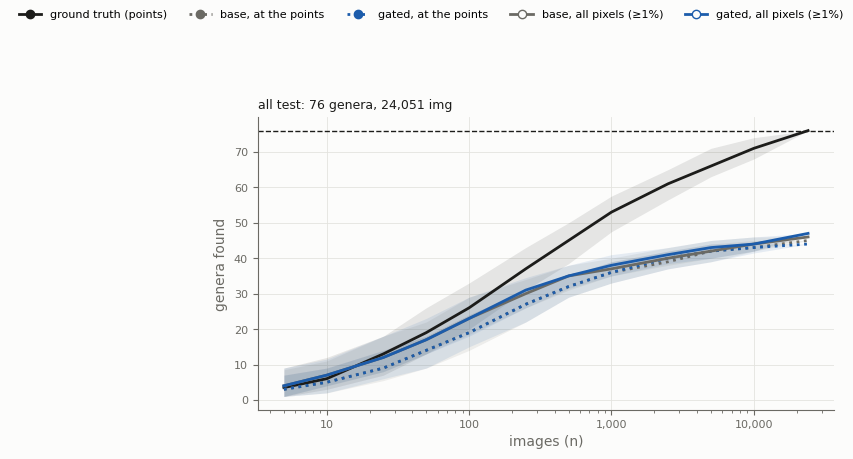

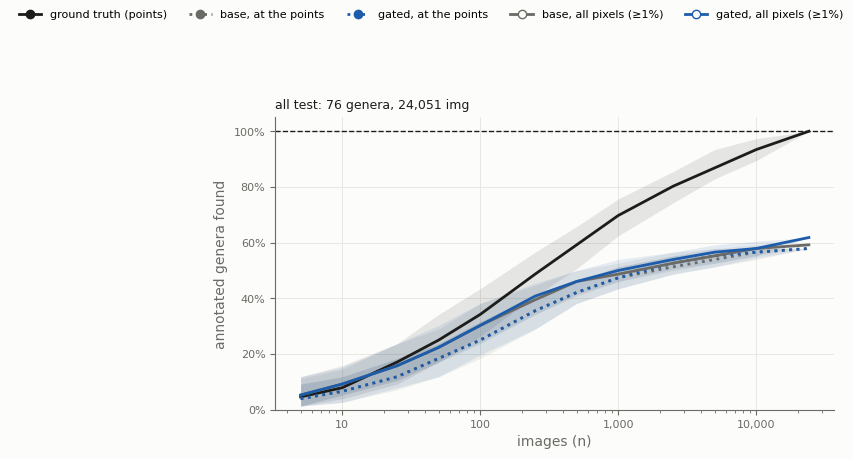

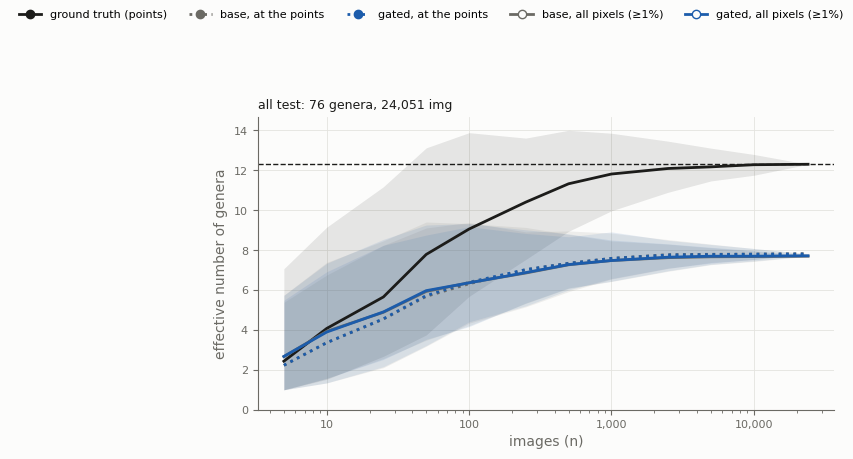

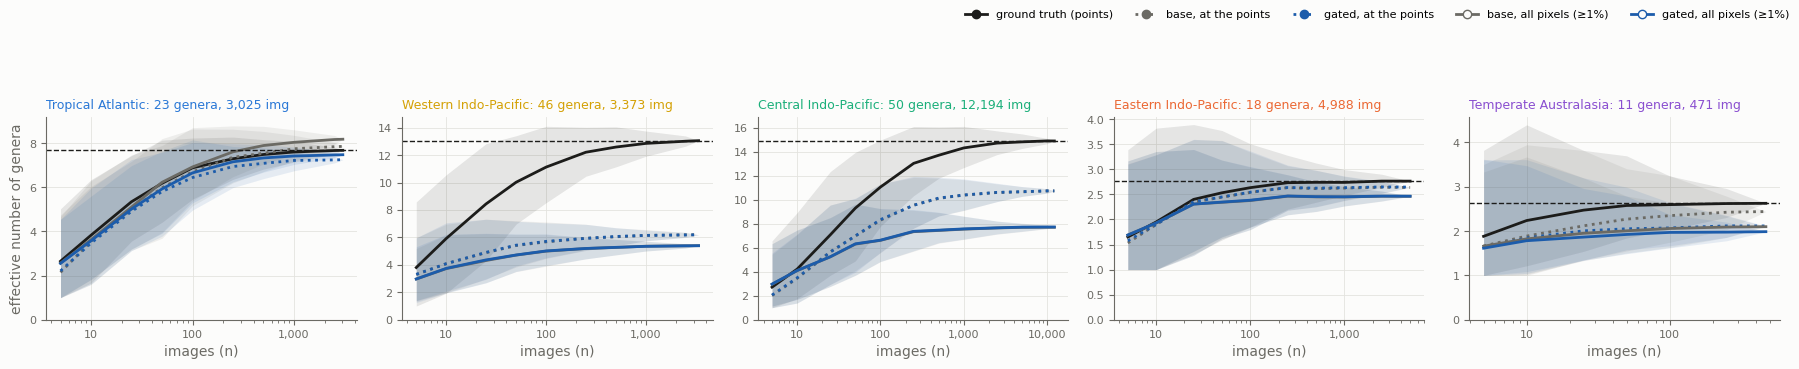

In [17]:
for kind in ("rich", "recall"):
    grid_plot({"all test": ACC["all test"]}, "all", kind, ncols=1, panel=(6.5, 3.8))
grid_plot({"all test": HILL["all test"]}, "all", "hill", ncols=1, panel=(6.5, 3.8))
grid_plot({g: HILL[g] for g in REGIONS}, "realm", "hill", ncols=len(REGIONS), fname="effective_number_realm.png")

### 7.3 Which genera: relative abundance, all test data pooled

Each genus's share of the annotated live coral genus points against its share of the model's genus pixels (all
pixels, ≥ `TAU`), base vs gated (log axes; dashed 1:1, band: within 2×). Marker area ∝ the number of images in which
the genus is annotated. Annotated genera the model never predicts sit on the bottom edge (open markers). Labelled: the
15 most abundant annotated genera and every genus off by more than 3×.

base, at the points         : annotated never predicted 32; predicted never annotated  1: fimbriaphyllia (0.00%)
gated, at the points        : annotated never predicted 32; predicted never annotated  0
base, all pixels (≥1%)      : annotated never predicted 31; predicted never annotated  1: fimbriaphyllia (0.00%)
gated, all pixels (≥1%)     : annotated never predicted 29; predicted never annotated  0


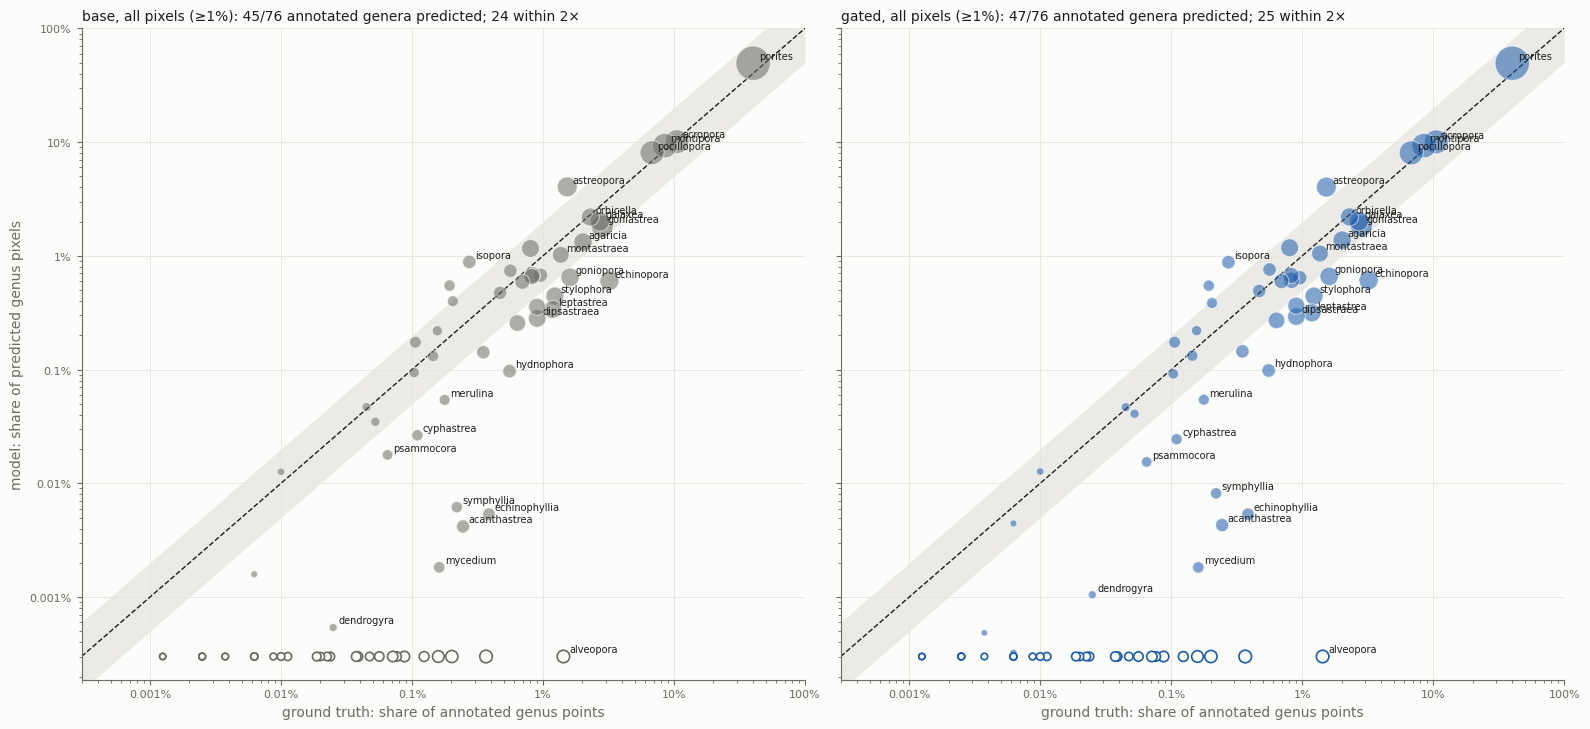

In [18]:
rows_all = DROWS["all"]["all test"]
comp = pd.DataFrame({k: abundance(rows_all, k).sum(axis=0) for k in ESTIMATES}, index=TAXA)
comp = comp / comp.sum()
comp["images (GT)"] = (abundance(rows_all, "truth") > 0).sum(axis=0)
for k in MODEL_KEYS:
    comp[f"images ({k})"] = (abundance(rows_all, k) > 0).sum(axis=0)
comp = comp.sort_values("truth", ascending=False)
comp.to_csv(OUT / "genus_relative_abundance.csv")

for k in MODEL_KEYS:
    missing = comp[(comp.truth > 0) & (comp[k] == 0)].index
    false = comp[(comp.truth == 0) & (comp[k] > 0)][k].sort_values(ascending=False)
    print(f"{ESTIMATES[k][0]:28s}: annotated never predicted {len(missing):2d}; predicted never annotated {len(false):2d}"
          + (": " + ", ".join(f"{g} ({v:.2%})" for g, v in false.head(8).items()) if len(false) else ""))

FLOOR = 3e-6
pct_fmt = mticker.FuncFormatter(lambda v, _: f"{100 * v:.3g}%")
c = comp[comp.truth > 0]
gt = c.truth
size = 12 + 600 * np.sqrt(c["images (GT)"] / c["images (GT)"].max())
fig, axes = plt.subplots(1, 2, figsize=(16, 7.4), sharex=True, sharey=True)
for ax, key in zip(axes, ("base_dense", "gate_dense")):
    label, color, _, _ = ESTIMATES[key]
    m = c[key]
    zero = m == 0
    ax.fill_between([FLOOR, 1], [FLOOR / 2, 0.5], [FLOOR * 2, 2], color="#ebeae6", lw=0, zorder=0)
    ax.plot([FLOOR, 1], [FLOOR, 1], color=INK, lw=1, ls="--", zorder=1)
    ax.scatter(gt[~zero], m[~zero], s=size[~zero], color=color, alpha=0.55, edgecolor="white", lw=0.8, zorder=3)
    ax.scatter(gt[zero], np.full(zero.sum(), FLOOR), s=size[zero], facecolor=SURFACE, edgecolor=color, lw=1.2, zorder=3)
    ratio = m / gt
    for g_ in set(gt.nlargest(15).index) | set(c.index[~zero & ((ratio > 3) | (ratio < 1 / 3)) & (gt > 1e-4)]):
        ax.annotate(g_, (gt[g_], m[g_] if m[g_] > 0 else FLOOR), xytext=(4, 3), textcoords="offset points",
                    fontsize=7, color=INK)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(FLOOR, 1)
    ax.set_ylim(FLOOR / 1.6, 1)
    ax.xaxis.set_major_formatter(pct_fmt)
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_xlabel("ground truth: share of annotated genus points")
    r = c[key] / gt
    ax.set_title(f"{label}: {int((~zero).sum())}/{len(c)} annotated genera predicted; "
                 f"{int(r.between(0.5, 2).sum())} within 2×")
axes[0].set_ylabel("model: share of predicted genus pixels")
fig.tight_layout()
fig.savefig(OUT / "genus_relative_abundance.png", dpi=150)
plt.show()

Per realm: the genera whose all-pixel share changes most with gating. A positive change moves the genus's share
towards (or past) its annotated share; negative changes are mostly out-of-realm genera the gate removes. Shares are
of the realm's live coral genus pixels.

In [19]:
rows = []
for r_, rr in DROWS["realm"].items():
    s = {k: abundance(rr, k).sum(axis=0) for k in ("truth", "base_dense", "gate_dense")}
    s = {k: v / v.sum() for k, v in s.items()}
    d = pd.DataFrame({"annotated": s["truth"], "base": s["base_dense"], "gated": s["gate_dense"]}, index=TAXA)
    d["Δ (gated − base)"] = d.gated - d.base
    d["|error| base"] = (d.base - d.annotated).abs()
    d["|error| gated"] = (d.gated - d.annotated).abs()
    top = d.reindex(d["Δ (gated − base)"].abs().sort_values(ascending=False).index).head(8)
    rows.append(top.assign(realm=r_).set_index("realm", append=True).swaplevel())
SHIFT = pd.concat(rows)
SHIFT.index.names = ["realm", "genus"]
SHIFT.to_csv(OUT / "genus_share_shift_per_realm.csv")
SHIFT.style.format("{:.2%}")

## 8. Summary

In [20]:
a = CLS["all"].loc["all test"]
print(f"Pooled point classification (annotated live hard coral genus points; uncertain if p ≤ {THRESH}):")
for k in METRICS:
    print(f"  {k:15s} " + "  ".join(f"{m} {a[(k, m)]:.3f}" for m in METHODS))
print("\nPooled Δ vs base, 95% bootstrap CI:")
for (m, k), r in DELTA.iterrows():
    print(f"  {m:14s} {k:15s} {r['Δ']:+.4f} [{r['Δ lo']:+.4f}, {r['Δ hi']:+.4f}]")
t = CLS["source"]
for m in GATES:
    d = t[("accuracy", m)] - t[("accuracy", "base")]
    f = t[("macro F1", m)] - t[("macro F1", "base")]
    print(f"\n{m}: accuracy up in {(d > 1e-9).sum()}/{len(d)} sources, down in {(d < -1e-9).sum()}; "
          f"macro F1 up in {(f > 1e-9).sum()}, down in {(f < -1e-9).sum()}; "
          f"largest accuracy gain {d.max():+.3f} ({d.idxmax()}), largest loss {d.min():+.3f} ({d.idxmin()})")
print("\nDiversity, all test pooled (richness | genus-list precision / recall | composition similarity):")
d_all = DSUM["all"].loc["all test"]
print(f"  ground truth richness {int(d_all[('richness', 'truth')])}")
for k in MODEL_KEYS:
    print(f"  {ESTIMATES[k][0]:28s} {int(d_all[('richness', k)]):3d} | {d_all[('precision', k)]:.2f} / "
          f"{d_all[('recall', k)]:.2f} | {d_all[('composition similarity', k)]:.2f}")
print("\nDiversity per realm, all pixels: richness error base → gated, precision base → gated, recall base → gated:")
for g in REGIONS:
    r_ = DDELTA.loc[(g, "all pixels")]
    t_ = DSUM["realm"].loc[g]
    print(f"  {g:22s} richness {int(r_['richness error base']):+d} → {int(r_['richness error gated']):+d}; "
          f"precision {t_[('precision', 'base_dense')]:.2f} → {t_[('precision', 'gate_dense')]:.2f}; "
          f"recall {t_[('recall', 'base_dense')]:.2f} → {t_[('recall', 'gate_dense')]:.2f}")
print("\nPer realm, accuracy / macro F1 / coverage:")
r = CLS["realm"]
for g in r.index:
    print(f"  {g:22s} " + "  ".join(f"{m} {r.loc[g, ('accuracy', m)]:.3f}/{r.loc[g, ('macro F1', m)]:.3f}/"
                                     f"{r.loc[g, ('coverage', m)]:.2f}" for m in METHODS))

Pooled point classification (annotated live hard coral genus points; uncertain if p ≤ 0.5):
  accuracy        base 0.671  gate iNat+ann 0.675
  balanced acc.   base 0.238  gate iNat+ann 0.243
  macro F1        base 0.266  gate iNat+ann 0.271
  weighted F1     base 0.730  gate iNat+ann 0.733
  coverage        base 0.839  gate iNat+ann 0.847
  selective acc.  base 0.800  gate iNat+ann 0.797

Pooled Δ vs base, 95% bootstrap CI:
  gate iNat+ann  accuracy        +0.0044 [+0.0038, +0.0050]
  gate iNat+ann  balanced acc.   +0.0048 [+0.0037, +0.0064]
  gate iNat+ann  macro F1        +0.0048 [+0.0037, +0.0065]
  gate iNat+ann  weighted F1     +0.0029 [+0.0023, +0.0035]
  gate iNat+ann  coverage        +0.0084 [+0.0075, +0.0092]
  gate iNat+ann  selective acc.  -0.0027 [-0.0034, -0.0020]

gate iNat+ann: accuracy up in 18/18 sources, down in 0; macro F1 up in 16, down in 2; largest accuracy gain +0.029 (6702), largest loss +0.001 (1990)

Diversity, all test pooled (richness | genus-list precision

### Findings (run of 2026-11-12, `THRESH` = 0.5; compared with the 256 px KL05 model in `Genus_Geographic_Gating.ipynb`)

- **This model is much stronger, so there is less for gating to fix.** Base accuracy is 0.671 (KL05: 0.511),
  macro F1 0.266 (0.157), and 16% of points are `uncertain` (KL05: 25%). With gating:
  - accuracy +0.44 pp [+0.38, +0.50] (KL05: +0.67);
  - macro F1 +0.48 pp (KL05: +0.73);
  - coverage +0.8 pp (KL05: +1.7).
- **Gating is still never harmful.** 0 correct base predictions become wrong or uncertain. Accuracy goes up in 18/18
  sources (largest gain source 6702, +2.9 pp). As before, most changes are `uncertain` → genus (317 correct,
  442 wrong) rather than wrong → correct (35).
- **The Tropical Atlantic again gains the most** (accuracy 0.617 → 0.633). This model makes far fewer Indo-Pacific
  calls on Caribbean reefs than the 256 px model, but they still show up in the genus lists.
- **Diversity: gating gives the same genus-list clean-up as for KL05.** All pixels (≥ 1%), base → gated:

  | realm | genus-list precision | recall |
  |---|---|---|
  | Tropical Atlantic | 0.43 → 1.00 | 0.57 → 0.61 |
  | Central Indo-Pacific | 0.83 → 0.97 | 0.68 → 0.72 |
  | Western Indo-Pacific | 0.78 → 0.88 | 0.61 → 0.61 |
  | Temperate Australasia | 0.44 → 0.57 | 0.73 → 0.73 |
  | Eastern Indo-Pacific | unchanged | unchanged |

  The resolution does not remove the out-of-realm genera, so the gate is as useful for the genus lists here as for
  the 256 px model, even though point accuracy gains are smaller.
- **Richness.** In the Tropical Atlantic, base overestimates by 7 genera (spurious) and gated underestimates by 9.
  Elsewhere the model under-counts by 8–14 genera, less than KL05 (8–22). Gating cannot fix under-counting.
- **Pooled over all test data the gated all-pixel list is clean** (precision 0.98 → 1.00; the base model's one
  never-annotated genus, *Fimbriaphyllia*, is removed). Recall rises 0.59 → 0.62. Effective number and composition
  barely change.
